# Solar Home System (SHS) Analytics & Product Design Decision
**Energy Data Analytics (04-782) · Carnegie Mellon University**
**Andrew ID:** tdukundi · **Case Study 2:** Solar Home Systems

---

**Business question.** What panel and battery sizes should a PAYGo company offer, and can a few standard products
serve customers nearly as well as sizing each customer individually?

| § | Stage | Question it answers |
|---|---|---|
| 1 | Data preparation | Is the data clean? Which window do we compare? |
| 2 | How much energy | How much do customers use, and how consistently? |
| 3 | When energy is used | Which daily patterns recur? |
| 4 | Change over time | Does use repeat weekly? Does it change after a year? |
| 5 | Sizing | What battery and panel does each customer need? |
| 6 | Product design | How many customers do 1–4 standard kits cover? |
| 7 | Synthesis | Question → observation → explanation → recommendation |
| 8 | **Outage & assumption investigation** | Are low-use spells caused by no sun, the battery, payment or data? |

**Scope.** The CSV holds hourly consumption only (Wh). It has no PV generation, battery state, payments, appliances,
calendar dates or installation age, so results are **hypotheses for the company to test**.

## 0. Setup
Only general settings live here. Battery and PV assumptions are defined in their own sections (§5).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


WINDOW_DAYS = 365          # first 365 elapsed days per system
SEED        = 42

DAY_HOURS   = list(range(6, 18))                     # 06:00–17:59
NIGHT_HOURS = list(range(18, 24)) + list(range(0, 6))  # 18:00–05:59 of the same elapsed day

## 1. Data preparation
### 1.1 Load and check the raw data
Rules: keep recorded zeros, never fill missing values with zero, and require 24 valid hours for a daily total.

In [3]:
df = pd.read_csv('final_anon_hourly.csv', index_col=0)
df.index = pd.RangeIndex(len(df))          # elapsed hour 0, 1, 2, ...

values = df.to_numpy()
print(f"Systems: {df.shape[1]:,} | hourly rows: {df.shape[0]:,} (= {df.shape[0] / 24:,.0f} days)")
print(f"Non-numeric / negative / inf: {df.dtypes.ne(float).sum()} / {(values < 0).sum()} / {np.isinf(values).sum()}")

Systems: 1,000 | hourly rows: 29,568 (= 1,232 days)
Non-numeric / negative / inf: 0 / 0 / 0


In [4]:
last_valid = df.apply(pd.Series.last_valid_index)
internal_missing = sum(df[c].iloc[: last_valid[c] + 1].isna().sum() for c in df.columns)
valid = pd.Series(values[np.isfinite(values)])

print(f"Internal missing hours: {internal_missing}")
print(f"Valid hourly observations: {len(valid):,}")
print(f"Zero hours: {(valid == 0).mean():.2%} of valid hours")

Internal missing hours: 0
Valid hourly observations: 15,499,344
Zero hours: 2.32% of valid hours


> **Interpretation.** The data is clean: 1,000 systems, no negative, infinite or non-numeric values, and **no gaps inside records**.
> All missing values are trailing blanks that simply mark where a record ends. Only 2.3% of valid hours are zero,
> so most systems draw some energy almost every hour.

### 1.2 Daily totals and record length

count   1,000.00
mean      646.00
std       205.00
min       391.00
25%       479.00
50%       591.00
75%       771.00
max     1,232.00
dtype: float64

Zero days: 1.91% of complete days


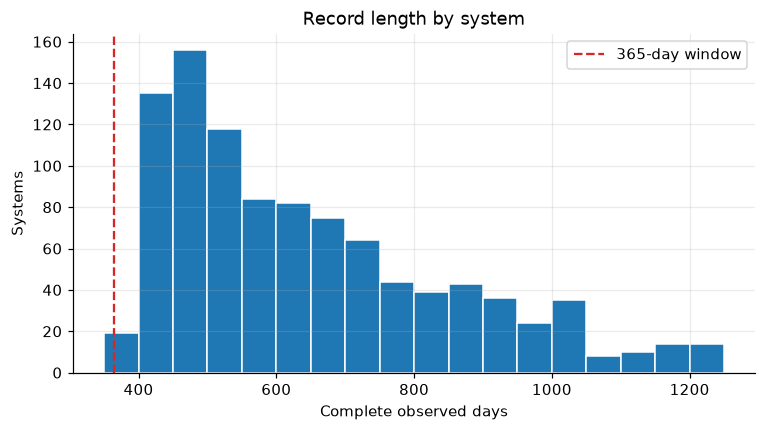

In [5]:
day_idx = df.index // 24
daily = df.groupby(day_idx).sum(min_count=24)       # NaN unless all 24 hours are valid
daily.index.name = "elapsed_day"

complete_days = daily.notna().sum()
daily_valid = pd.Series(daily.to_numpy()[daily.notna().to_numpy()])
print(complete_days.describe().round(0))
print(f"\nZero days: {(daily_valid == 0).mean():.2%} of complete days")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(complete_days, bins=np.arange(350, 1300, 50), edgecolor="white")
ax.axvline(WINDOW_DAYS, color="C3", ls="--", label=f"{WINDOW_DAYS}-day window")
ax.set(title="Record length by system", xlabel="Complete observed days", ylabel="Systems")
ax.legend(); plt.show()

> **Interpretation.** Records range from **391 to 1,232 days** (median 591). The histogram is right-skewed: most systems have 400–600 days
> and few exceed 1,000. Because every system has at least 391 days, the **first 365 days** give a fair common window.
> Long-record systems cannot be compared with short ones directly, since elapsed days do not share calendar dates.

In [ ]:
pct = [0, .01, .5, .99, 1]
pd.DataFrame({"Hourly Wh": valid.quantile(pct).values, "Daily Wh": daily_valid.quantile(pct).values},
             index=["Min", "P1", "Median", "P99", "Max"])

> **Interpretation.** A typical hour uses **1.4 Wh** and a typical day **49 Wh**, roughly one LED bulb plus phone charging.
> The daily 99th percentile (184 Wh) is almost 4× the median, and the maximum (580 Wh) is 12× the median.
> Sizing to the average would therefore fail on high-use days, while sizing to the maximum would waste capacity.

### 1.3 Common window: first 365 elapsed days

In [6]:
hourly_365 = df.iloc[: WINDOW_DAYS * 24]
daily_365  = daily.iloc[:WINDOW_DAYS]
h365 = hourly_365.index % 24          # clock hour
d365 = hourly_365.index // 24         # elapsed day

assert daily_365.notna().all().all()
print("daily_365:", daily_365.shape, "| every system has 365 complete days")

daily_365: (365, 1000) | every system has 365 complete days


> **Interpretation.** All 1,000 systems have 365 complete days, so every customer statistic below uses the same amount of data.

### 1.4 A first look: four random customers (seed 42, first week)

['System_439', 'System_89', 'System_654', 'System_773']


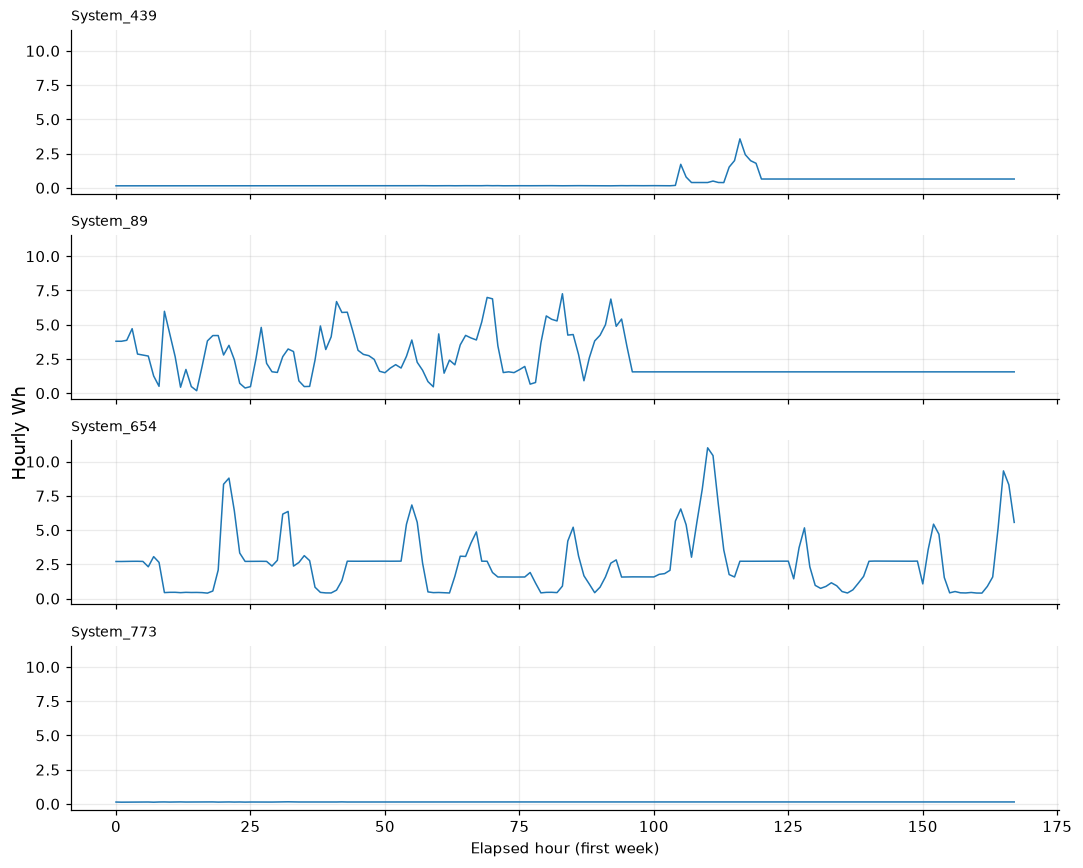

In [7]:
rng = np.random.default_rng(SEED)
example_systems = list(rng.choice(df.columns, size=4, replace=False))
print(example_systems)

fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, s in zip(axes, example_systems):
    ax.plot(df[s].iloc[:168].values, lw=1)
    ax.set_title(s, fontsize=9, loc="left")
axes[-1].set_xlabel("Elapsed hour (first week)")
fig.supylabel("Hourly Wh"); plt.tight_layout(); plt.show()

> **Interpretation.** The four customers behave very differently. System_654 has clear daily evening peaks. System_89 is active for four
> days and then drops to a **perfectly flat line**. System_439 and System_773 sit on near-constant low values.
> Real appliance use is never exactly constant for days, so these flat segments suggest **either standby load (a
> controller or always-on device) or gap-filled telemetry**. This matters for sizing and outages and is tested in §8.1.

## 2. How much energy? Level and consistency
### 2.1 Customer statistics (first 365 days)
* **Mean** = energy volume; **median** = a typical day (resists occasional high days).
* **IQR** = Q75 − Q25 = day-to-day spread; **IQR / median** = relative spread.
* **Q90** = the sizing target used in §5.

In [8]:
q25, q75 = daily_365.quantile(0.25), daily_365.quantile(0.75)

customer_stats = pd.DataFrame({
    "Mean_Wh":   daily_365.mean(),
    "Median_Wh": daily_365.median(),
    "Std_Wh":    daily_365.std(),
    "IQR_Wh":    q75 - q25,
    "Q90_Wh":    daily_365.quantile(0.90),
    "Max_Wh":    daily_365.max(),
    "Zero_days": (daily_365 == 0).sum(),
})
customer_stats["IQR_over_Median"]   = customer_stats["IQR_Wh"] / customer_stats["Median_Wh"].where(customer_stats["Median_Wh"] > 0)
customer_stats["Mean_minus_Median"] = customer_stats["Mean_Wh"] - customer_stats["Median_Wh"]

display(customer_stats.head())
customer_stats.describe(percentiles=[.1, .5, .9]).T[["mean", "10%", "50%", "90%", "max"]]

,Mean_Wh,Median_Wh,Std_Wh,IQR_Wh,Q90_Wh,Max_Wh,Zero_days,IQR_over_Median,Mean_minus_Median
System_1,35.24,7.29,46.20,65.37,113.56,215.48,1,8.96,27.95
System_2,92.57,105.93,51.68,76.43,147.33,232.57,0,0.72,-13.37
System_3,25.46,17.79,26.60,43.83,63.45,109.61,4,2.46,7.66
System_4,33.90,40.06,18.36,21.78,50.48,102.46,3,0.54,-6.16
System_5,31.16,6.10,60.07,1.77,146.28,261.74,13,0.29,25.06


,mean,10%,50%,90%,max
Mean_Wh,60.43,28.75,56.38,98.89,153.27
Median_Wh,58.03,7.77,56.88,104.44,154.48
Std_Wh,36.26,17.54,32.46,59.39,127.60
IQR_Wh,47.70,17.62,41.55,88.92,154.51
Q90_Wh,104.27,59.56,95.24,158.39,425.09
Max_Wh,196.56,94.71,172.70,361.52,580.33
Zero_days,5.16,0.00,0.00,15.10,168.00
IQR_over_Median,3.25,0.33,0.68,3.14,302.52
Mean_minus_Median,2.40,-7.48,-0.28,19.30,81.63


> **Interpretation.** The median customer uses **57 Wh on a typical day** and **95 Wh on a high day (Q90)**. The spread across
> customers is wide: the 10th percentile is 8 Wh/day and the 90th percentile is 104 Wh/day.
> Zero days are rare for most customers (the median customer has none), but a few have up to 168 zero days.
> Those are candidates for outage investigation in §8.

### 2.2 Distribution of customer means and medians (20 Wh/day bins)

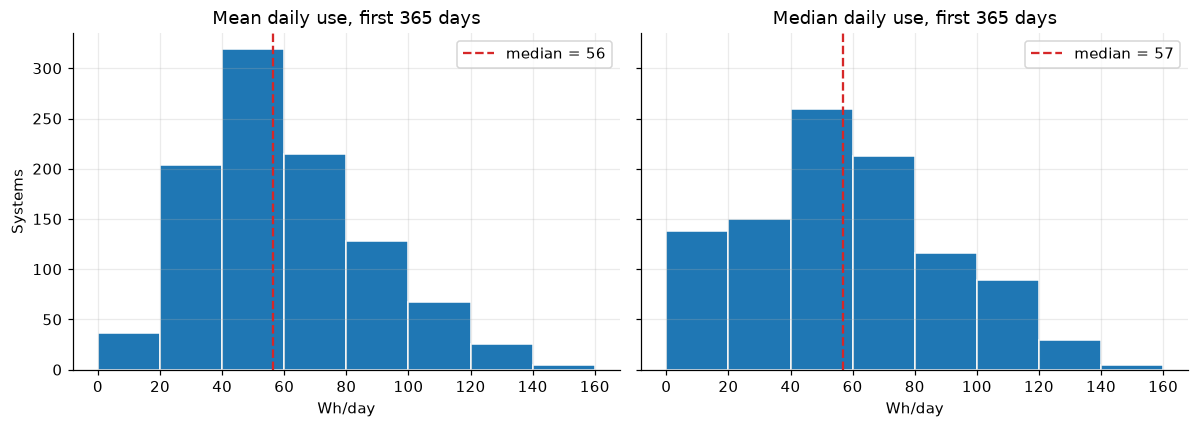

Mean > median for 48% of customers
Customers with median < 20 Wh/day: 138 vs mean < 20 Wh/day: 36
Correlation of mean and median across customers: 0.936


In [9]:
bins = np.arange(0, customer_stats[["Mean_Wh", "Median_Wh"]].max().max() + 20, 20)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, col in zip(axes, ["Mean_Wh", "Median_Wh"]):
    ax.hist(customer_stats[col], bins=bins, edgecolor="white")
    ax.axvline(customer_stats[col].median(), color="C3", ls="--", label=f"median = {customer_stats[col].median():.0f}")
    ax.set(title=f"{col.split('_')[0]} daily use, first 365 days", xlabel="Wh/day"); ax.legend()
axes[0].set_ylabel("Systems"); plt.tight_layout(); plt.show()

print(f"Mean > median for {(customer_stats['Mean_minus_Median'] > 0).mean():.0%} of customers")
print(f"Customers with median < 20 Wh/day: {(customer_stats['Median_Wh'] < 20).sum()} "
      f"vs mean < 20 Wh/day: {(customer_stats['Mean_Wh'] < 20).sum()}")
print(f"Correlation of mean and median across customers: {customer_stats['Mean_Wh'].corr(customer_stats['Median_Wh']):.3f}")

> **Interpretation.** Both distributions centre on about **56–57 Wh/day**, and mean and median agree closely across customers (r = 0.94).
> Only **48%** of customers have mean > median, so right-skew is *not* universal.
> The important difference is in the lowest bin: about **138 customers have a median under 20 Wh/day, but only 37 have a
> mean that low**. About 100 customers are therefore **"on/off" users**: most days are near-idle, and a minority of days
> carry heavy use. Their typical day understates their needs, so sizing must use a high percentile.

### 2.3 Within-customer variability

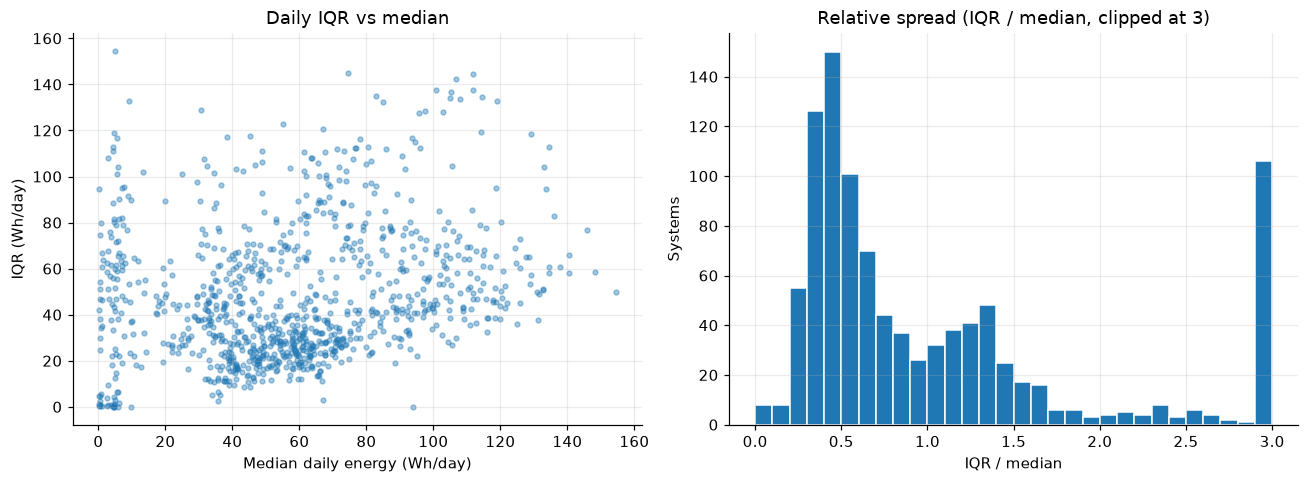

Spearman (median vs IQR): 0.25
Customers whose IQR exceeds their median: 37.5%


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(customer_stats["Median_Wh"], customer_stats["IQR_Wh"], s=10, alpha=.4)
axes[0].set(title="Daily IQR vs median", xlabel="Median daily energy (Wh/day)", ylabel="IQR (Wh/day)")
rel = customer_stats["IQR_over_Median"].dropna()
axes[1].hist(rel.clip(upper=3), bins=30, edgecolor="white")
axes[1].set(title="Relative spread (IQR / median, clipped at 3)", xlabel="IQR / median", ylabel="Systems")
plt.tight_layout(); plt.show()

print(f"Spearman (median vs IQR): {customer_stats['Median_Wh'].corr(customer_stats['IQR_Wh'], method='spearman'):.2f}")
print(f"Customers whose IQR exceeds their median: {(rel > 1).mean():.1%}")

> **Interpretation.** Spread is only weakly tied to level (Spearman **0.25**): customers with the same median can differ by 100 Wh/day in IQR.
> The left panel shows a **vertical band at median ≈ 0–10 Wh with IQR up to 150 Wh**, the on/off users from §2.2.
> The right panel has two modes. About half of customers are **steady** (IQR ≈ 0.4–0.6 × median). A second group is
> **irregular** (≈ 1.2–1.4 ×), plus ~100 extreme cases (> 3 ×). **37.5%** of customers vary by more than their typical day,
> so variability, not just level, must drive battery sizing.

### 2.4 Daytime and nighttime energy
Computed per elapsed day from hourly data (day = 06–17 h, night = 18–05 h), then summarized per customer.
Night energy must pass through the battery.

In [14]:
is_day = pd.Series(h365).isin(DAY_HOURS).to_numpy()

E_day   = hourly_365[is_day].groupby(d365[is_day]).sum(min_count=12)
E_night = hourly_365[~is_day].groupby(d365[~is_day]).sum(min_count=12)
assert np.allclose((E_day + E_night).to_numpy(), daily_365.to_numpy())

day_night = pd.DataFrame({
    "Median_Day_Wh":   E_day.median(),
    "Median_Night_Wh": E_night.median(),
    "Night_Share":     E_night.sum() / daily_365.sum(),
})
day_night["Time_Profile"] = pd.cut(day_night["Night_Share"], [-np.inf, .40, .60, np.inf],
                                   labels=["Daytime-heavy", "Balanced", "Nighttime-heavy"])
display(day_night.head())
display(day_night["Time_Profile"].value_counts().to_frame("Systems"))

,Median_Day_Wh,Median_Night_Wh,Night_Share,Time_Profile
System_1,3.42,3.65,0.40,Balanced
System_2,63.17,38.26,0.37,Daytime-heavy
System_3,7.20,8.08,0.52,Balanced
System_4,17.52,20.59,0.54,Balanced
System_5,3.20,2.90,0.45,Balanced


,Systems
Time_Profile,
Balanced,571
Nighttime-heavy,219
Daytime-heavy,210


> **Interpretation.** **57% of customers are balanced** (40–60% of energy at night), **22% are night-heavy** and **21% are day-heavy**.
> Because the split is close to even for most customers, a large part of their energy passes through the battery.
> System_2 shows why individual checks matter: it has a strong evening peak, yet it is *day-heavy* overall because its
> daytime use is long even though it is less intense.

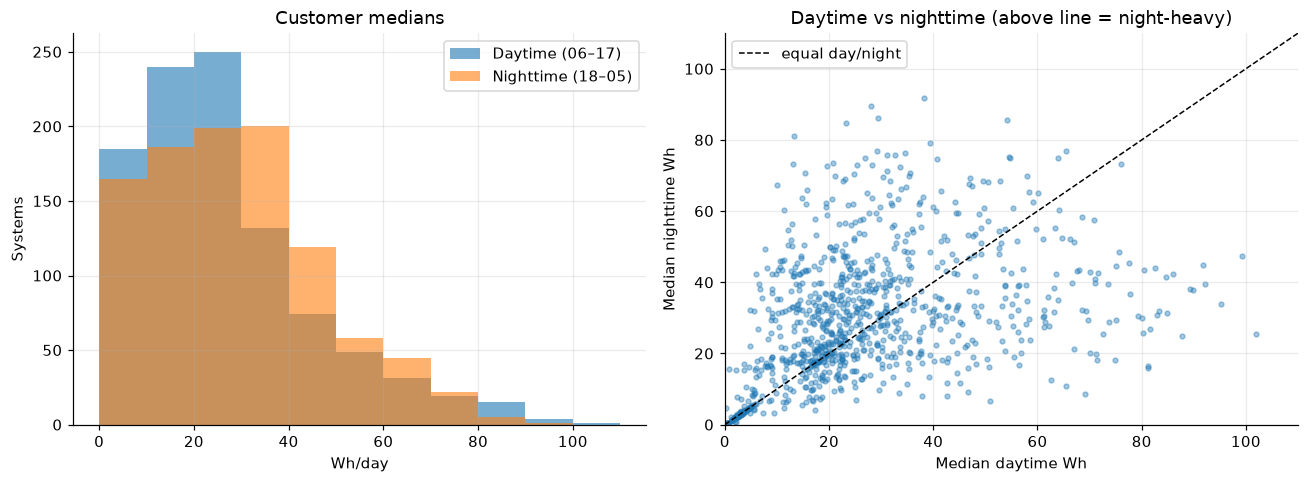

Customers using more at night than by day: 54.6%


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
b = np.arange(0, day_night[["Median_Day_Wh", "Median_Night_Wh"]].max().max() + 10, 10)
axes[0].hist(day_night["Median_Day_Wh"], bins=b, alpha=.6, label="Daytime (06–17)")
axes[0].hist(day_night["Median_Night_Wh"], bins=b, alpha=.6, label="Nighttime (18–05)")
axes[0].set(title="Customer medians", xlabel="Wh/day", ylabel="Systems"); axes[0].legend()

lim = b[-1]
axes[1].scatter(day_night["Median_Day_Wh"], day_night["Median_Night_Wh"], s=10, alpha=.4)
axes[1].plot([0, lim], [0, lim], "k--", lw=1, label="equal day/night")
axes[1].set(title="Daytime vs nighttime (above line = night-heavy)", xlabel="Median daytime Wh",
            ylabel="Median nighttime Wh", xlim=(0, lim), ylim=(0, lim)); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"Customers using more at night than by day: {(day_night['Median_Night_Wh'] > day_night['Median_Day_Wh']).mean():.1%}")

> **Interpretation.** Night medians sit slightly to the right of day medians, and **54.6%** of customers use more at night on a typical day.
> In the scatter, points spread widely on both sides of the line, so timing is very individual. One feature stands out:
> a **tight line of points exactly on the diagonal at low energy (0–20 Wh)**. Customers with identical day and night use
> are consistent with a **constant hourly draw** (12 h × same value). This is the flat-line signal from §1.4, tested in §8.1.

## 3. When is energy used? Profile shapes
### 3.1 Hourly mean and median profiles (example systems)
The 24 hourly means sum to mean daily energy. Hourly medians show the *typical* hour but need not sum to the median day.

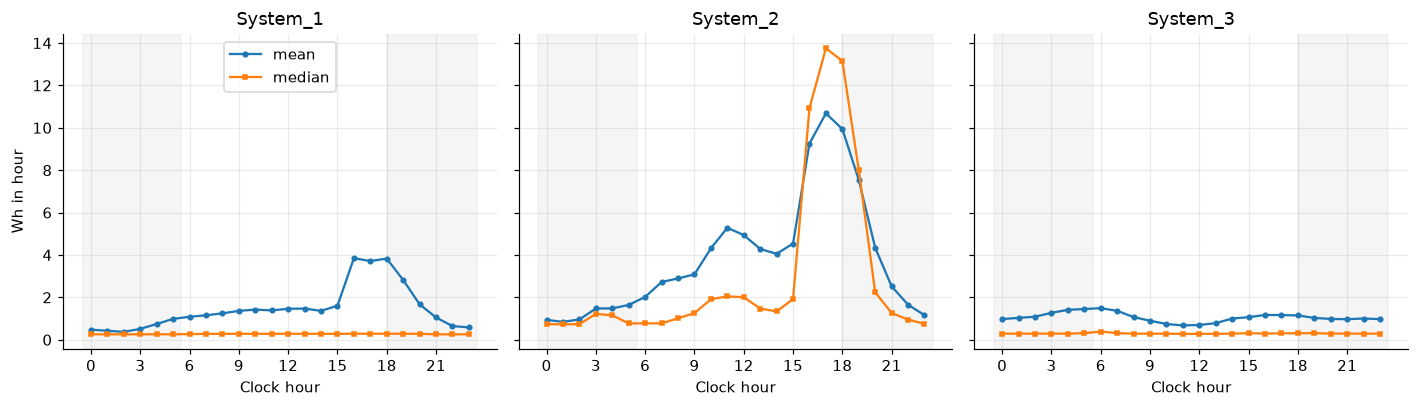

In [16]:
profile_mean   = hourly_365.groupby(h365).mean()     # 24 x N
profile_median = hourly_365.groupby(h365).median()

show = ["System_1", "System_2", "System_3"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, s in zip(axes, show):
    ax.plot(profile_mean[s], marker="o", ms=3, label="mean")
    ax.plot(profile_median[s], marker="s", ms=3, label="median")
    ax.axvspan(18, 23.5, color="grey", alpha=.08); ax.axvspan(-.5, 5.5, color="grey", alpha=.08)
    ax.set(title=s, xlabel="Clock hour", xticks=range(0, 24, 3))
axes[0].set_ylabel("Wh in hour"); axes[0].legend(); plt.tight_layout(); plt.show()

> **Interpretation.** **System_2** has a strong 16–19 h peak, and its median (≈ 14 Wh at 17 h) is *above* its mean. The evening peak is
> a **regular daily habit**, and occasional low days pull the mean down.
> **System_1** and **System_3** have median profiles flat at ≈ 0.3 Wh in every hour, while their means show shape. On a
> typical day they draw only a small constant load, and their visible pattern comes from a minority of active days.
> These are the on/off users.

### 3.2 Population profile and peak hour

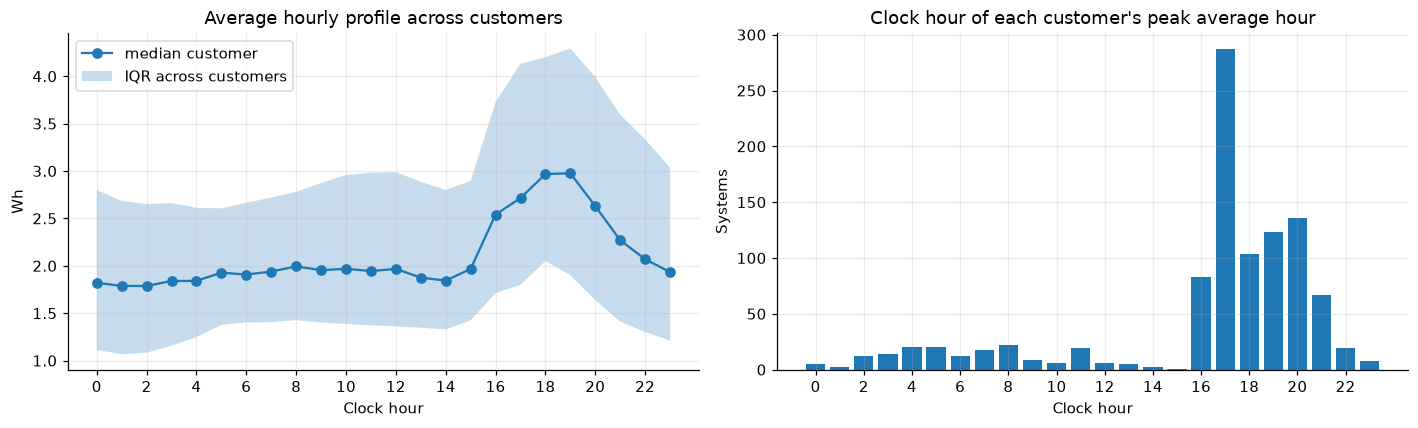

Customers peaking 17:00–20:59: 65.0%
Median overnight base load (00–04 h): 1.82 Wh/h ≈ 44 Wh/day if constant


In [17]:
peak_hour = profile_mean.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(profile_mean.median(axis=1), marker="o", label="median customer")
axes[0].fill_between(range(24), profile_mean.quantile(.25, axis=1), profile_mean.quantile(.75, axis=1),
                     alpha=.25, label="IQR across customers")
axes[0].set(title="Average hourly profile across customers", xlabel="Clock hour", ylabel="Wh", xticks=range(0, 24, 2))
axes[0].legend()
counts = peak_hour.value_counts().reindex(range(24), fill_value=0)
axes[1].bar(counts.index, counts.values)
axes[1].set(title="Clock hour of each customer's peak average hour", xlabel="Clock hour", ylabel="Systems",
            xticks=range(0, 24, 2))
plt.tight_layout(); plt.show()

base = profile_mean.loc[[0, 1, 2, 3, 4]].mean().median()
print(f"Customers peaking 17:00–20:59: {peak_hour.between(17, 20).mean():.1%}")
print(f"Median overnight base load (00–04 h): {base:.2f} Wh/h ≈ {base * 24:.0f} Wh/day if constant")

> **Interpretation.** The median customer draws a **near-constant ≈ 1.8 Wh every hour**, including 00–05 h, plus an evening bump to ≈ 3 Wh
> at 18–19 h. A constant 1.8 Wh/h equals ≈ **43 Wh/day, most of the median day (57 Wh)**. Consumption is therefore
> **dominated by an always-on base load** (e.g. a security light, radio, standby electronics or controller draw), and the
> evening peak adds relatively little. **65%** of customers peak between 17:00 and 20:59, with a sharp spike at **17:00**.
> A 17:00 lighting peak is early for the tropics. This raises the possibility that timestamps are not in local time (tested in §8.6).

### 3.3 Normalize by daily energy
Average first, then divide each hour by the sum of the 24 hourly means. Each row sums to 1, so clustering compares
**timing only**.

Excluded (zero total): 0 | shape: (1000, 24)


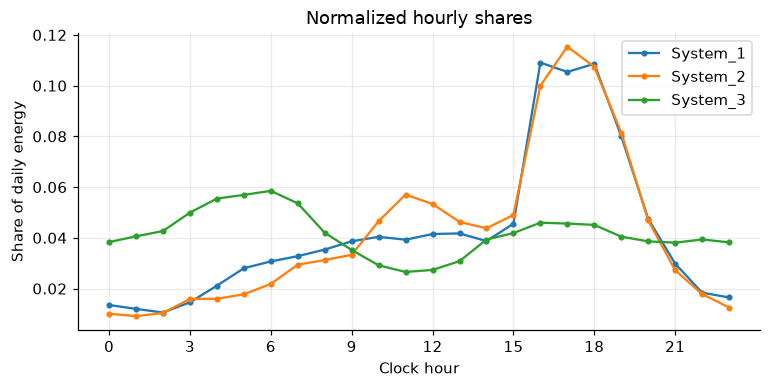

In [18]:
profiles_customer = profile_mean.T                   # N x 24
totals = profiles_customer.sum(axis=1)
normalized = profiles_customer.div(totals.where(totals > 0), axis=0).dropna()
assert np.allclose(normalized.sum(axis=1), 1)
print("Excluded (zero total):", len(profiles_customer) - len(normalized), "| shape:", normalized.shape)

fig, ax = plt.subplots(figsize=(8, 3.5))
for s in show:
    ax.plot(normalized.loc[s], marker="o", ms=3, label=s)
ax.set(title="Normalized hourly shares", xlabel="Clock hour", ylabel="Share of daily energy", xticks=range(0, 24, 3))
ax.legend(); plt.show()

> **Interpretation.** After normalization, System_1 and System_2 have **almost identical shapes** (≈ 11% of daily energy in each hour at 16–18 h),
> although System_2 uses about 3× more energy. System_3 stays flat at 3–6% per hour. This is what clustering needs:
> customers are grouped by *when* they use energy, not *how much*.

### 3.4 Choosing k: compare k = 3, 4, 5

,inertia,silhouette,smallest_group,largest_group
k,,,,
2,5.51,0.30,343,657
3,4.73,0.23,218,474
4,4.19,0.21,158,412
5,3.75,0.21,153,316
6,3.40,0.21,87,295
7,3.17,0.21,24,286
8,3.00,0.19,24,208


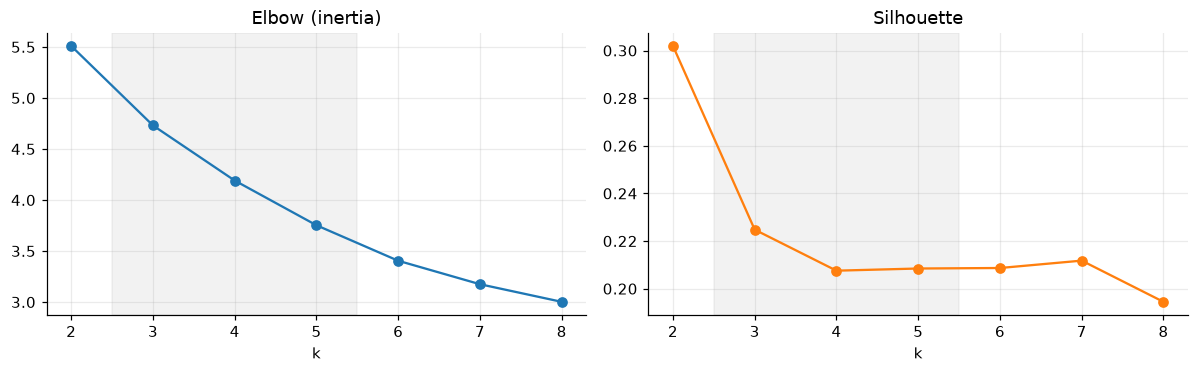

In [19]:
X = normalized.to_numpy()
rows, fits = [], {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=SEED, n_init=20).fit(X)
    fits[k] = km
    sizes = np.bincount(km.labels_)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_),
                 "smallest_group": sizes.min(), "largest_group": sizes.max()})
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_table.index, k_table["inertia"], marker="o"); axes[0].set(title="Elbow (inertia)", xlabel="k")
axes[1].plot(k_table.index, k_table["silhouette"], marker="o", color="C1"); axes[1].set(title="Silhouette", xlabel="k")
for ax in axes: ax.axvspan(2.5, 5.5, color="grey", alpha=.1)
plt.tight_layout(); plt.show()

> **Interpretation.** The elbow curve declines smoothly with **no sharp elbow**, and silhouette falls from 0.30 (k = 2) to a plateau of
> ≈ **0.21 for k = 4–6**. Silhouette values near 0.2 mean the groups **overlap**: load shapes form a *continuum* rather
> than distinct types. k = 4 is chosen because it keeps every group large (≥ 158 systems) and separates timing patterns
> that matter for storage (checked below), not because it is a statistical optimum.

In [20]:
for k in [3, 4, 5]:
    c = pd.DataFrame(fits[k].cluster_centers_)
    ns = c[NIGHT_HOURS].sum(axis=1).sort_values()
    print(f"k={k}: night share of centers = {np.round(ns.values, 2)}  sizes = {np.bincount(fits[k].labels_)[ns.index]}")

k=3: night share of centers = [0.37 0.45 0.6 ]  sizes = [218 308 474]
k=4: night share of centers = [0.37 0.41 0.59 0.59]  sizes = [176 254 412 158]
k=5: night share of centers = [0.36 0.37 0.52 0.6  0.62]  sizes = [159 158 316 153 214]


> **Interpretation.** Going from k = 3 to k = 4 splits the night-leaning group into **two groups with the same night share (0.59) but
> different peak timing** (see §3.5). Going to k = 5 only adds another low-night-share group. k = 4 therefore adds useful
> detail, while k = 5 adds little for storage decisions.

### 3.5 Final segmentation (k = 4), relabelled A → D by night share

In [21]:
K = 4
km = fits[K]
centers = pd.DataFrame(km.cluster_centers_, columns=range(24))
order = centers[NIGHT_HOURS].sum(axis=1).sort_values().index
names = {old: chr(ord("A") + i) for i, old in enumerate(order)}
cluster = pd.Series(km.labels_, index=normalized.index).map(names).rename("Cluster")
centers = centers.rename(index=names).sort_index()

cluster_summary = pd.DataFrame({
    "Systems": cluster.value_counts().sort_index(),
    "Night_share_center": centers[NIGHT_HOURS].sum(axis=1),
    "Peak_hour_center": centers.idxmax(axis=1),
    "Peak_share_center": centers.max(axis=1),
})
cluster_summary["Share_%"] = cluster_summary["Systems"] / len(cluster) * 100
cluster_summary

,Systems,Night_share_center,Peak_hour_center,Peak_share_center,Share_%
A,176,0.37,17,0.11,17.60
B,254,0.41,17,0.06,25.40
C,412,0.59,19,0.06,41.20
D,158,0.59,20,0.09,15.80


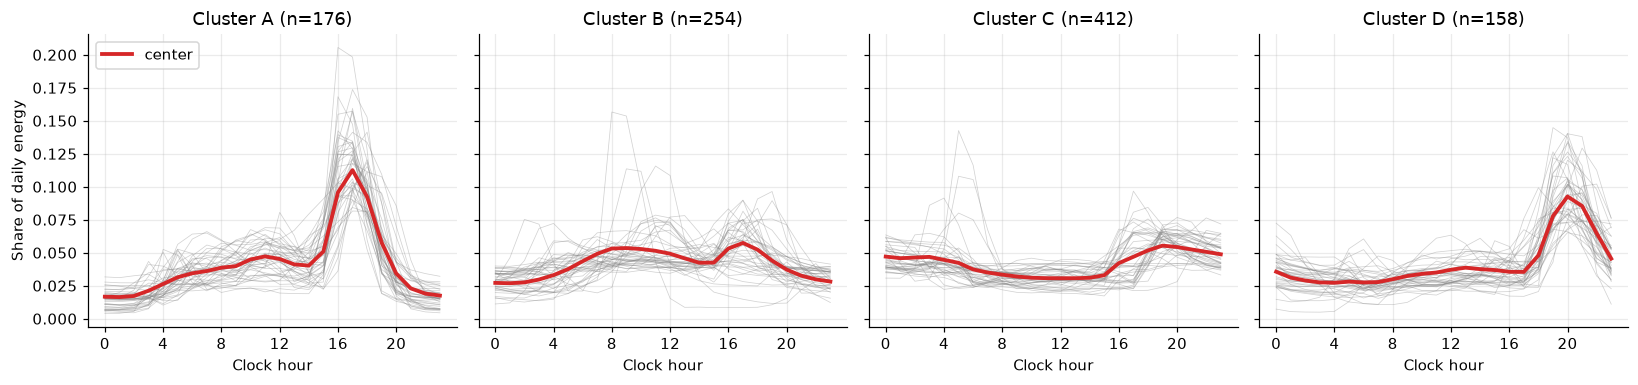

In [22]:
fig, axes = plt.subplots(1, K, figsize=(15, 3.6), sharey=True)
for ax, c in zip(axes, centers.index):
    members = normalized[cluster == c]
    for s in members.sample(min(40, len(members)), random_state=SEED).index:
        ax.plot(members.loc[s].values, color="grey", lw=.5, alpha=.35)
    ax.plot(centers.loc[c].values, lw=2.5, color="C3", label="center")
    ax.set(title=f"Cluster {c} (n={len(members)})", xlabel="Clock hour", xticks=range(0, 24, 4))
axes[0].set_ylabel("Share of daily energy"); axes[0].legend()
plt.tight_layout(); plt.show()

> **Interpretation.** | Cluster | Size | Shape | Plain-language label |
> |---|---|---|---|
> | **A** | 176 (18%) | Sharp peak 16–18 h (≈ 11% per hour), low night | *Early-evening peak* |
> | **B** | 254 (25%) | Broad daytime plateau 08–13 h, small 17 h bump | *Daytime / productive use* |
> | **C** | 412 (41%) | Nearly flat, slightly higher overnight | *Flat base load* |
> | **D** | 158 (16%) | Late peak at 20 h, low morning | *Late-evening peak* |
> 
 The largest group, C, is the **flat profile**, which
> fits the base-load finding in §3.2. Member lines (grey) spread widely around each center, confirming the weak separation.

### 3.6 Shape vs absolute energy

,Systems,Median_of_median_Wh,Median_Q90_Wh,P10_Q90_Wh,P90_Q90_Wh,Median_night_share
Cluster,,,,,,
A,176,72.15,124.23,60.52,160.15,0.38
B,254,51.67,88.75,56.43,150.87,0.43
C,412,52.11,85.55,56.51,130.82,0.58
D,158,82.97,144.06,84.01,181.91,0.58


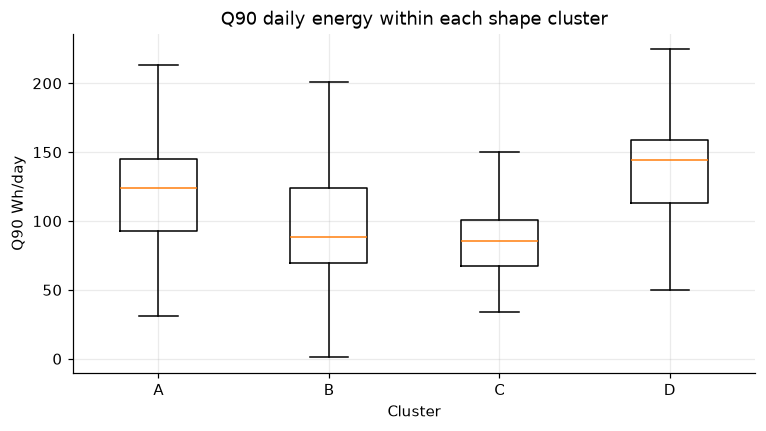

In [23]:
seg = customer_stats.join(day_night).join(cluster)
cluster_energy = seg.groupby("Cluster").agg(
    Systems=("Median_Wh", "size"),
    Median_of_median_Wh=("Median_Wh", "median"),
    Median_Q90_Wh=("Q90_Wh", "median"),
    P10_Q90_Wh=("Q90_Wh", lambda s: s.quantile(.1)),
    P90_Q90_Wh=("Q90_Wh", lambda s: s.quantile(.9)),
    Median_night_share=("Night_Share", "median"),
)
display(cluster_energy)

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([seg.loc[seg.Cluster == c, "Q90_Wh"] for c in centers.index], tick_labels=centers.index, showfliers=False)
ax.set(title="Q90 daily energy within each shape cluster", xlabel="Cluster", ylabel="Q90 Wh/day"); plt.show()

> **Interpretation.** Shape and size are related but overlap heavily. **Peaky clusters use more energy**: D (late peak) has a median Q90 of
> **144 Wh** and A (early peak) **124 Wh**, versus **86–89 Wh** for flat C and daytime B.
> Yet every cluster spans roughly 60 → 150+ Wh (P10–P90), so **a shape label cannot set the kit size**.
> Shape tells us *when* energy is used; kit size must come from *how much* energy is used.

## 4. Change over time
### 4.1 ACF and PACF of daily consumption (lags 1–28)
* **ACF** = correlation between today and *k* days ago.
* **PACF** = the same, after removing the effect of the days in between.

Orange boxes = multiples of 7. Seven-day positions are not known weekdays.

In [24]:
LAGS = range(1, 29)

def acf_pairs(x, lags):
    out = []
    for k in lags:
        u, v = x[k:], x[:-k]
        out.append(np.corrcoef(u, v)[0, 1] if u.std() > 0 and v.std() > 0 else np.nan)
    return out

def pacf_regression(x, lags):
    x = np.asarray(x, float); n = len(x); out = []
    for k in lags:
        y, z = x[k:], x[: n - k]
        Z = np.column_stack([np.ones(n - k)] + [x[k - j: n - j] for j in range(1, k)])
        e = y - Z @ np.linalg.lstsq(Z, y, rcond=None)[0]
        f = z - Z @ np.linalg.lstsq(Z, z, rcond=None)[0]
        out.append(np.corrcoef(e, f)[0, 1] if e.std() > 1e-12 and f.std() > 1e-12 else np.nan)
    return out

acf_df  = pd.DataFrame({s: acf_pairs(daily_365[s].to_numpy(), LAGS) for s in daily_365}, index=LAGS)
pacf_df = pd.DataFrame({s: pacf_regression(daily_365[s].to_numpy(), LAGS) for s in daily_365}, index=LAGS)
pacf_ok = pacf_df.dropna(axis=1)
print(f"ACF systems: {acf_df.shape[1]} | PACF systems defined at every lag: {pacf_ok.shape[1]}")

ACF systems: 1000 | PACF systems defined at every lag: 996


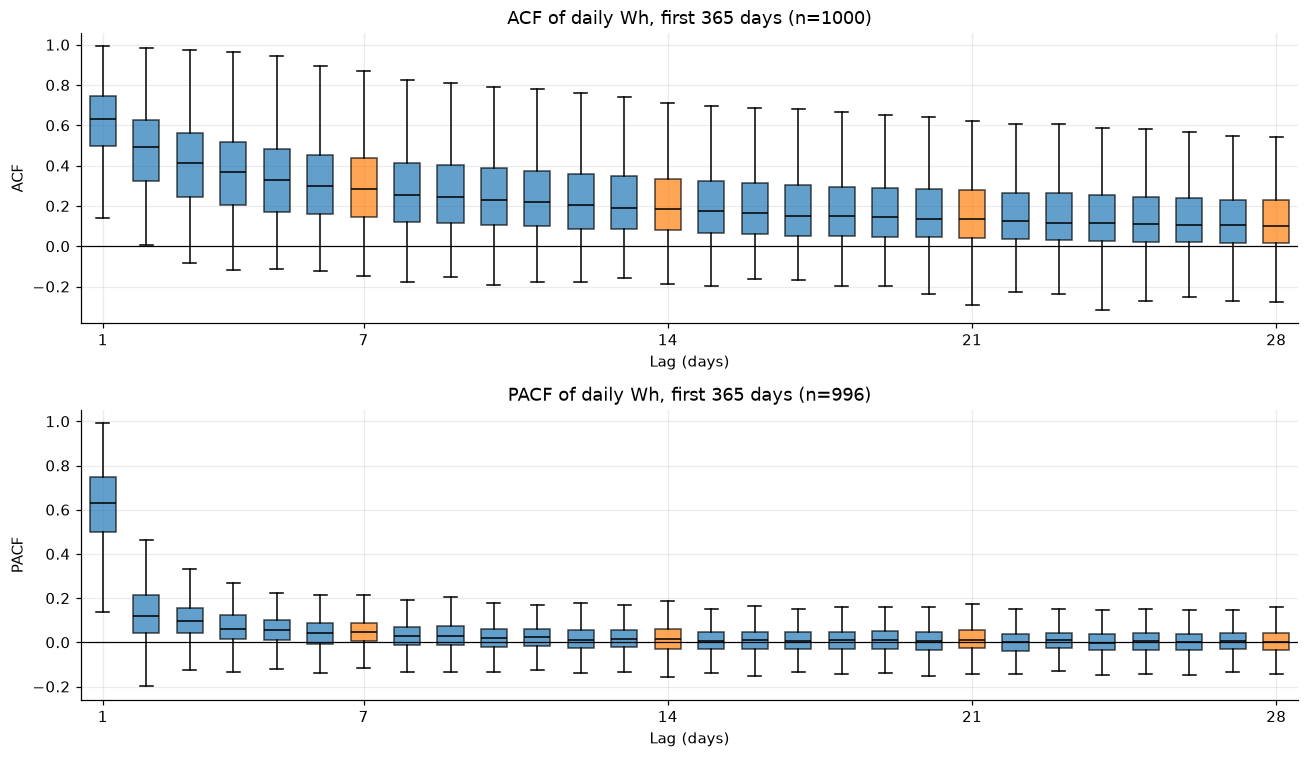

Median ACF lag 1 / 7 / 14 / 28: [0.632, 0.281, 0.184, 0.101]
Weekly ACF bump vs neighbouring lags (7, 14, 21): [0.004 0.002 0.005]
Median PACF lag 1 / 2 / 7 / 14: [0.632, 0.118, 0.045, 0.016]


In [25]:
def lag_boxplot(ax, table, title):
    bp = ax.boxplot([table.loc[k].dropna() for k in LAGS], positions=list(LAGS), showfliers=False,
                    patch_artist=True, widths=.6, medianprops={"color": "black"})
    for k, box in zip(LAGS, bp["boxes"]):
        box.set_facecolor("C1" if k % 7 == 0 else "C0"); box.set_alpha(.7)
    ax.axhline(0, color="k", lw=.8)
    ax.set_xticks([1, 7, 14, 21, 28], labels=["1", "7", "14", "21", "28"])
    ax.set(title=title, xlabel="Lag (days)")

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
lag_boxplot(axes[0], acf_df,  f"ACF of daily Wh, first 365 days (n={acf_df.shape[1]})")
lag_boxplot(axes[1], pacf_ok, f"PACF of daily Wh, first 365 days (n={pacf_ok.shape[1]})")
axes[0].set_ylabel("ACF"); axes[1].set_ylabel("PACF"); plt.tight_layout(); plt.show()

med_acf, med_pacf = acf_df.median(axis=1), pacf_ok.median(axis=1)
bump = med_acf[[7, 14, 21]].values - (med_acf[[6, 13, 20]].values + med_acf[[8, 15, 22]].values) / 2
print("Median ACF lag 1 / 7 / 14 / 28:", med_acf[[1, 7, 14, 28]].round(3).tolist())
print("Weekly ACF bump vs neighbouring lags (7, 14, 21):", np.round(bump, 3))
print("Median PACF lag 1 / 2 / 7 / 14:", med_pacf[[1, 2, 7, 14]].round(3).tolist())

> **Interpretation.** **Strong short-term memory.** The median ACF is **0.63 at lag 1** and still **0.10 at lag 28**, decaying slowly without
> reaching zero. A high-use day is usually followed by more high-use days, and low spells also persist.
> **No weekly cycle at the population level.** The orange boxes are only ≈ 0.004 above their neighbours, and the PACF
> drops to ≈ 0.12 at lag 2 and ≈ 0 by lag 7 (0.045).
> Almost all the memory is carried by *yesterday* (AR(1)-like), so the lecture's weekly-pattern suggestion is **not
> supported for the typical customer**. §4.2 checks whether a minority still show one.
> **Sizing implication:** high-use and low-sun days both cluster in runs, so one day of autonomy may be too little (see §8.5).

### 4.2 Is any 7-day pattern stable across both halves of the year?
For each customer, compare the 7-position profile of days 0–181 with days 182–363. A real weekly routine repeats.

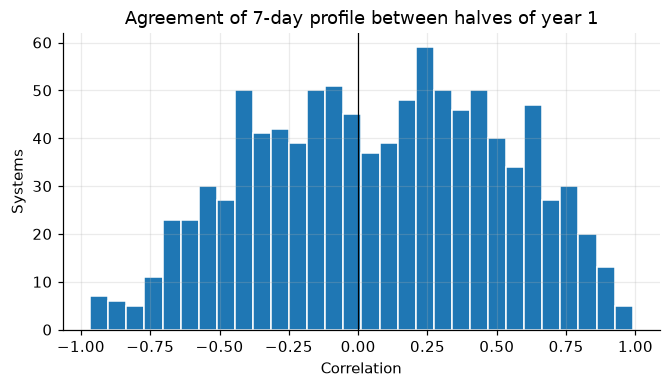

Median correlation: 0.09 | share > 0.5: 19.8%


In [26]:
def weekly_profile(block):
    block = block.reset_index(drop=True)
    return block.groupby(np.arange(len(block)) % 7).mean() / block.mean()

half_corr = {}
for s in daily_365:
    a, b = weekly_profile(daily_365[s].iloc[:182]), weekly_profile(daily_365[s].iloc[182:364])
    half_corr[s] = a.corr(b) if a.std() > 0 and b.std() > 0 else np.nan
half_corr = pd.Series(half_corr).dropna()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(half_corr, bins=30, edgecolor="white"); ax.axvline(0, color="k", lw=.8)
ax.set(title="Agreement of 7-day profile between halves of year 1", xlabel="Correlation", ylabel="Systems"); plt.show()
print(f"Median correlation: {half_corr.median():.2f} | share > 0.5: {(half_corr > .5).mean():.1%}")

> **How to read this (run the cell).** If the histogram centres near **0**, weekly shapes do not repeat and the ACF
> result above holds. A clear bulge above **0.5** would identify a *minority* of customers with genuine weekly routines
> (e.g. market days or worship days), who could be targeted separately. With 7 positions, random correlations of
> ± 0.5 are common, so treat only a large share (≫ 20%) above 0.5 as evidence.

### 4.3 Long-term patterns (full records, 30-day rolling statistics with ≥ 30 complete days)

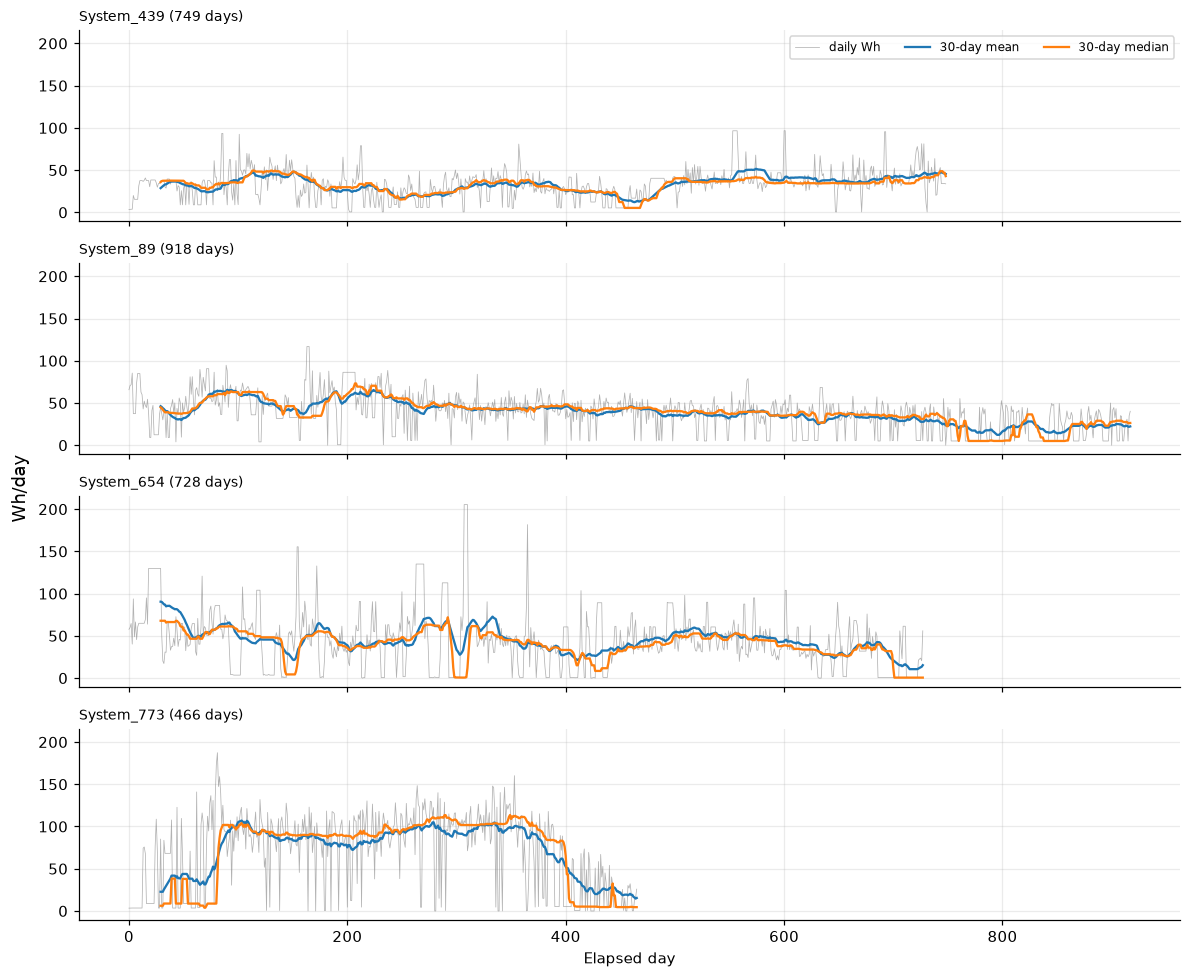

In [27]:
roll_mean   = daily.rolling(30, min_periods=30).mean()
roll_median = daily.rolling(30, min_periods=30).median()

fig, axes = plt.subplots(len(example_systems), 1, figsize=(11, 9), sharex=True, sharey=True)
for ax, s in zip(axes, example_systems):
    n = int(complete_days[s])
    ax.plot(daily[s].iloc[:n], color="grey", lw=.5, alpha=.6, label="daily Wh")
    ax.plot(roll_mean[s].iloc[:n], color="C0", label="30-day mean")
    ax.plot(roll_median[s].iloc[:n], color="C1", label="30-day median")
    ax.set_title(f"{s} ({n} days)", fontsize=9, loc="left")
axes[0].legend(ncol=3, fontsize=8); axes[-1].set_xlabel("Elapsed day")
fig.supylabel("Wh/day"); plt.tight_layout(); plt.show()

> ** Look for **level shifts**: sudden steps up (new appliance?) or down (fault,
> lockout, battery ageing), and **gaps between the mean and median lines**. A mean above the median means a few
> high days in that window; a median near zero with a positive mean means an on/off period. A gradual slope downward
> over hundreds of days is consistent with battery ageing, while a sharp drop is consistent with an event.

### 4.4 Year-over-year change: days 0–89 vs 365–454 (≥ 81 matched days)

Eligible: 857 | excluded: 143
Lower one year later: 528 of 857 (62%)
Median change: -6.2 Wh/day


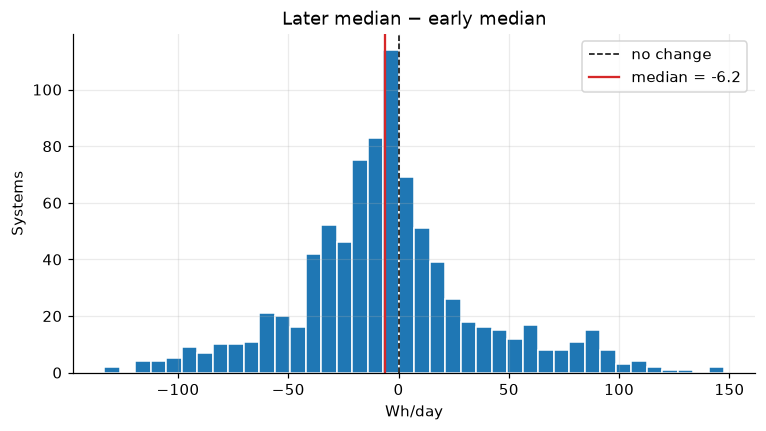

In [28]:
early = daily.iloc[0:90].reset_index(drop=True)
later = daily.iloc[365:455].reset_index(drop=True)
matched = early.notna() & later.notna()
eligible = matched.sum()[lambda s: s >= 81].index

yoy = pd.DataFrame({
    "Early_median": early[eligible].where(matched[eligible]).median(),
    "Later_median": later[eligible].where(matched[eligible]).median(),
})
yoy["Change_Wh"] = yoy["Later_median"] - yoy["Early_median"]

n_down = (yoy["Change_Wh"] < 0).sum()
print(f"Eligible: {len(yoy)} | excluded: {df.shape[1] - len(yoy)}")
print(f"Lower one year later: {n_down} of {len(yoy)} ({n_down / len(yoy):.0%})")
print(f"Median change: {yoy['Change_Wh'].median():.1f} Wh/day")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(yoy["Change_Wh"], bins=40, edgecolor="white")
ax.axvline(0, color="k", ls="--", lw=1, label="no change")
ax.axvline(yoy["Change_Wh"].median(), color="C3", label=f"median = {yoy['Change_Wh'].median():.1f}")
ax.set(title="Later median − early median", xlabel="Wh/day", ylabel="Systems"); ax.legend(); plt.show()

> **Interpretation.** **528 of 857 eligible systems (62%) use less one year later**, with a median change of **−6.2 Wh/day (≈ −14%)**,
> exactly matching the lecture. The histogram is roughly symmetric around −6 with long tails in both directions
> (−130 to +150 Wh/day). The typical customer declines slightly, but individual trajectories range from large increases to large drops.

In [29]:
yoy_seg = yoy.join(cluster)
yoy_seg["Start_level"] = pd.qcut(yoy_seg["Early_median"], 4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
display(yoy_seg.groupby("Cluster")["Change_Wh"].agg(size="size", median="median",
        share_declined=lambda s: (s < 0).mean()))
display(yoy_seg.groupby("Start_level", observed=True)["Change_Wh"].agg(["size", "median"]))

,size,median,share_declined
Cluster,,,
A,155,0.26,0.50
B,213,-5.51,0.62
C,351,-8.66,0.66
D,138,-9.18,0.63


,size,median
Start_level,,
Q1 low,215,32.29
Q2,214,-4.82
Q3,214,-15.45
Q4 high,214,-25.70


> **Interpretation.** The decline is **not uniform**:
> * **By starting level:** the lowest quartile *rises* by +32 Wh/day, while the highest quartile falls by −26 Wh/day.
>   This is the classic signature of **regression to the mean**: customers measured on an unusually low or high
>   90-day window drift back toward their normal level. Part of the "decline" is therefore a statistical artefact.
> * **By cluster:** early-peak A is flat (+0.3, 50% declined), while late-peak D (−9.2) and flat C (−8.7) decline most.
>   Heavy late-evening users rely most on the battery, so a larger decline is consistent with **battery ageing
>   capping their evening use**, one of the hypotheses tested in §8.

## 5. Sizing calculations
Sizing returns to **absolute daily Wh**, because normalized shapes remove the energy scale.

### 5.1 Sizing assumptions (Lecture 7 & 8)

In [31]:
q = 0.90          # demand target: 90th percentile of daily energy
D = 1             # days of full-load autonomy

# ---- Battery chemistry ----
# Lead-acid (historical case system)
DoD_lead     = 0.50
eta_rt_lead  = 0.80
eta_dis_lead = np.sqrt(eta_rt_lead)     # 0.894 (equal charge/discharge split)

# LFP (current SHS products)
DoD_lfp      = 0.80
eta_rt_lfp   = 0.92
eta_dis_lfp  = np.sqrt(eta_rt_lfp)      # 0.959

# ---- PV ----
f_pv     = 0.85          # derating (dust, heat, wiring, controller)
psh_list = [3, 4, 5]     # low-season peak sun hours/day (locations unknown)

# Check against Lecture 8 worked example: 40 Wh day + 60 Wh night, lead-acid, 1 day, 4 PSH
print("Battery:", round((40 + 60) / (DoD_lead * eta_dis_lead)), "Wh  (expect ≈ 224)")
print("PV:     ", round((40 + 60 / eta_rt_lead) / (4 * f_pv)), "Wp  (expect ≈ 34)")

Battery: 224 Wh  (expect ≈ 224)
PV:      34 Wp  (expect ≈ 34)


> **Interpretation.** Both formulas reproduce the lecture's worked example, so the code implements the method correctly.

### 5.2 Battery sizing
$$B = \frac{D \times Q_{0.90}(E_{day}+E_{night})}{DoD \times \eta_{dis}}$$

,count,mean,std,min,25%,50%,75%,95%,max
Q90_daily_Wh,"1,000.00",104.27,43.15,1.12,72.99,95.24,133.46,175.02,425.09
Lead_acid_Wh,"1,000.00",233.15,96.49,2.51,163.21,212.96,298.44,391.35,950.52
LFP_Wh,"1,000.00",135.89,56.24,1.46,95.12,124.12,173.93,228.09,553.98


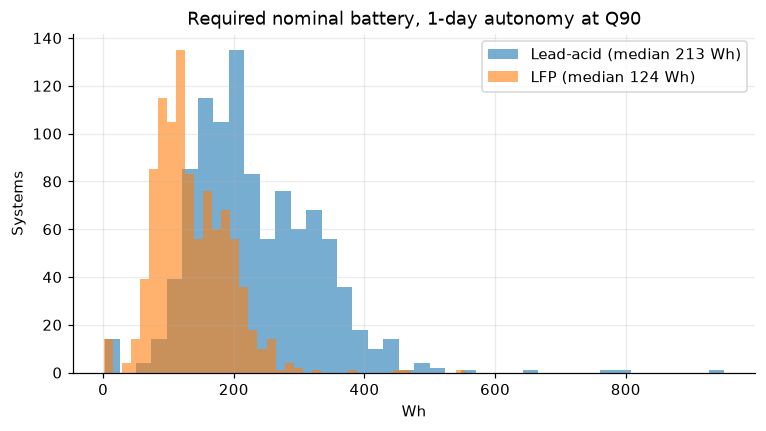

In [32]:
Q90_daily = daily_365.quantile(q)

battery_lead = D * Q90_daily / (DoD_lead * eta_dis_lead)
battery_lfp  = D * Q90_daily / (DoD_lfp  * eta_dis_lfp)

battery = pd.DataFrame({"Q90_daily_Wh": Q90_daily, "Lead_acid_Wh": battery_lead, "LFP_Wh": battery_lfp})
display(battery.describe(percentiles=[.25, .5, .75, .95]).T)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(battery_lead, bins=40, alpha=.6, label=f"Lead-acid (median {battery_lead.median():.0f} Wh)")
ax.hist(battery_lfp,  bins=40, alpha=.6, label=f"LFP (median {battery_lfp.median():.0f} Wh)")
ax.set(title="Required nominal battery, 1-day autonomy at Q90", xlabel="Wh", ylabel="Systems"); ax.legend(); plt.show()

> **Interpretation.** The median customer's Q90 day is **95 Wh**, requiring **≈ 124 Wh of LFP** or **≈ 213 Wh of lead-acid**
> (95% of customers are covered by ≤ 228 Wh LFP). LFP needs **≈ 42% less nominal capacity** for the same delivered
> energy because of its deeper usable DoD and higher efficiency.
> Note that the case system (12 V × 17 Ah ≈ 204 Wh lead-acid) sits right at the median requirement, so about half of
> customers would exceed it on their high days. This is a first hint of a **capacity ceiling** (tested in §8.4).

### 5.3 PV sizing
Night energy is inflated by battery losses: $E_{PV,t}=E_{day,t}+E_{night,t}/\eta_{rt}$, and
$P_{PV}=Q_{0.90}(E_{PV})/(H \times f_{PV})$.

,3 PSH,4 PSH,5 PSH
0.50,39.00,29.00,23.00
0.90,65.00,48.00,39.00
0.95,72.00,54.00,43.00


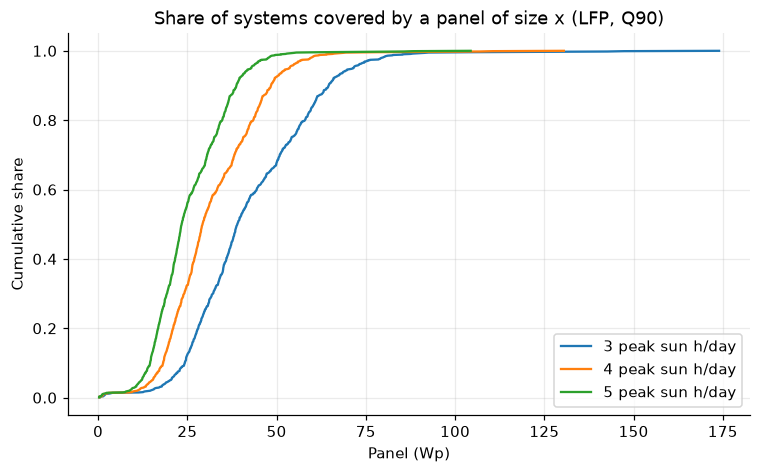

In [33]:
E_pv   = E_day + E_night / eta_rt_lfp
Q90_pv = E_pv.quantile(q)

pv = pd.DataFrame({f"{H} PSH": Q90_pv / (H * f_pv) for H in psh_list})
pv_4 = pv["4 PSH"]
display(pv.quantile([.5, .9, .95]).round(0))

fig, ax = plt.subplots(figsize=(8, 4.5))
for H in psh_list:
    v = np.sort(pv[f"{H} PSH"])
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), label=f"{H} peak sun h/day")
ax.set(title="Share of systems covered by a panel of size x (LFP, Q90)", xlabel="Panel (Wp)", ylabel="Cumulative share")
ax.legend(); plt.show()

> **Interpretation.** At **4 PSH the median customer needs ≈ 29 Wp** and 95% need ≤ 54 Wp. The site's sun resource matters as much as
> customer behaviour: going from 5 to 3 PSH raises the median panel from **23 to 39 Wp (+70%)**, and a 50 Wp panel
> covers ≈ 98% of customers at 5 PSH but only ≈ 70% at 3 PSH.
> **Knowing the service area's worst-month sun hours is therefore essential before fixing kit sizes.**

### 5.4 Sensitivity: demand target × autonomy (median customer, LFP, 4 PSH)

In [48]:
rows = []
for q_s in [0.80, 0.90, 0.95]:
    for D_s in [1, 2, 3]:
        b = D_s * daily_365.quantile(q_s) / (DoD_lfp * eta_dis_lfp)
        rows.append({"Target": f"Q{int(q_s*100)}", "Autonomy_days": D_s, "Median_battery_Wh": b.median()})
sens = pd.DataFrame(rows).pivot(index="Target", columns="Autonomy_days", values="Median_battery_Wh")
display(sens.round(0))

pv_sens = {f"Q{int(q_s*100)}": (E_pv.quantile(q_s) / (4 * f_pv)).median() for q_s in [0.80, 0.90, 0.95]}
print("Median PV (Wp):", {k: round(v, 1) for k, v in pv_sens.items()})

Autonomy_days,1,2,3
Target,,,
Q80,107.00,214.00,321.00
Q90,124.00,248.00,372.00
Q95,143.00,287.00,430.00


Median PV (Wp): {'Q80': np.float64(25.2), 'Q90': np.float64(29.3), 'Q95': np.float64(33.6)}


> **Interpretation.** Moving from Q80 to Q95 raises the median battery from **107 to 143 Wh (+34%)**, while each extra autonomy day adds a full
> **+124 Wh at Q90**. Autonomy therefore dominates battery cost: **2 days of autonomy costs more than going from Q80 to Q95**.
> The panel moves only from 25 to 34 Wp across targets.
> The choice of D should be driven by how long cloudy spells actually last, which is investigated in §8.5.

### 5.5 Does load timing change the hardware?

,Night_Share,PV_Wp_per_Q90_Wh,Night_only_vs_full
Cluster,,,
A,0.38,0.30,0.38
B,0.43,0.30,0.45
C,0.58,0.31,0.57
D,0.58,0.31,0.60


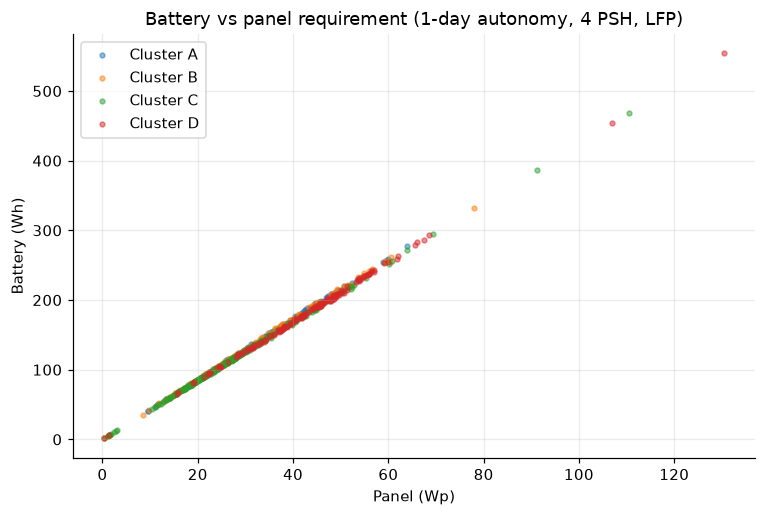

In [35]:
battery_night_only = E_night.quantile(q) / (DoD_lfp * eta_dis_lfp)   # storage to carry only the night load

sizing = pd.DataFrame({
    "Q90_daily_Wh": Q90_daily, "Battery_LFP_Wh": battery_lfp, "Battery_lead_Wh": battery_lead,
    "Battery_night_only_Wh": battery_night_only,
    "PV_3PSH_Wp": pv["3 PSH"], "PV_4PSH_Wp": pv_4, "PV_5PSH_Wp": pv["5 PSH"],
}).join(cluster)

g = sizing.join(day_night["Night_Share"])
g["PV_Wp_per_Q90_Wh"]   = g["PV_4PSH_Wp"] / g["Q90_daily_Wh"]
g["Night_only_vs_full"] = g["Battery_night_only_Wh"] / g["Battery_LFP_Wh"]
display(g.groupby("Cluster")[["Night_Share", "PV_Wp_per_Q90_Wh", "Night_only_vs_full"]].median().round(3))

fig, ax = plt.subplots(figsize=(8, 5))
for cl in centers.index:
    m = sizing["Cluster"] == cl
    ax.scatter(sizing.loc[m, "PV_4PSH_Wp"], sizing.loc[m, "Battery_LFP_Wh"], s=10, alpha=.5, label=f"Cluster {cl}")
ax.set(title="Battery vs panel requirement (1-day autonomy, 4 PSH, LFP)", xlabel="Panel (Wp)", ylabel="Battery (Wh)")
ax.legend(); plt.show()

> **Interpretation.** All customers lie on **one straight line (≈ 4.2 Wh of battery per Wp of panel)** whatever their cluster. Under this
> method, both battery and panel scale with the same Q90 daily energy, and timing changes panel size by only ≈ 3%
> (0.30 vs 0.31 Wp per Wh). **The lecture method is essentially one-dimensional.**
> Timing does matter for the *night-only* battery: day-leaning cluster A needs only **38%** of the full-autonomy battery
> to cover its nights, versus **60%** for late-peak D. If the company is willing to trade cloudy-day reserve for price,
> a **smaller-battery variant for day-heavy customers** is realistic. How much reserve is needed is tested in §8.5.

## 6. Product design: standard kits vs custom sizing
A kit covers a customer **only if both** its panel and its battery meet that customer's need.

**Method.** Scale index $s_i=\max(PV_i/\text{median }PV,\ B_i/\text{median }B)$. Tier breakpoints are set at
percentiles of $s$, and each tier is sized to the largest member need (rounded to 5 Wp / 10 Wh). The top tier covers
95% of customers; the rest go to a custom offer. Customers get the smallest kit that covers them.

In [49]:
req = pd.DataFrame({"PV": pv_4, "BAT": battery_lfp})
scale = np.maximum(req.PV / req.PV.median(), req.BAT / req.BAT.median())

def design_tiers(breaks):
    rows = []
    for i, b in enumerate(breaks):
        members = req[scale <= scale.quantile(b)]
        rows.append({"Tier": f"T{i+1}",
                     "PV_Wp": np.ceil(members.PV.max() / 5) * 5,
                     "Battery_Wh": np.ceil(members.BAT.max() / 10) * 10})
    return pd.DataFrame(rows)

def evaluate(tiers, r=req):
    assign = pd.Series("Not covered", index=r.index)
    for _, t in tiers[::-1].iterrows():                  # smallest covering tier wins
        assign[(r.PV <= t.PV_Wp) & (r.BAT <= t.Battery_Wh)] = t.Tier
    cov = assign != "Not covered"
    spec = tiers.set_index("Tier").loc[assign[cov]]
    return assign, {"Coverage_%": cov.mean() * 100,
                    "Excess_PV_%":   (spec.PV_Wp.values.sum() / r.PV[cov].sum() - 1) * 100,
                    "Excess_Batt_%": (spec.Battery_Wh.values.sum() / r.BAT[cov].sum() - 1) * 100}

OPTIONS = {"1 kit": [.95], "2 kits": [.60, .95], "3 kits": [.40, .75, .95], "4 kits": [.30, .60, .85, .95]}
results, catalogs, assignments = [], {}, {}
for name, br in OPTIONS.items():
    tiers = design_tiers(br); a, m = evaluate(tiers)
    catalogs[name], assignments[name] = tiers, a
    results.append({"Option": name, **m})
results.append({"Option": "Custom", "Coverage_%": 100.0, "Excess_PV_%": 0.0, "Excess_Batt_%": 0.0})
comparison = pd.DataFrame(results).set_index("Option")
display(comparison.round(1))

for name in ["3 kits", "4 kits"]:
    t = catalogs[name].copy()
    t["Customers"] = assignments[name].value_counts().reindex(t.Tier).values
    print(name); display(t)

,Coverage_%,Excess_PV_%,Excess_Batt_%
Option,,,
1 kit,95.30,81.20,78.00
2 kits,95.30,37.60,37.00
3 kits,95.30,30.80,24.30
4 kits,95.30,22.10,20.50
Custom,100.00,0.00,0.00


3 kits


,Tier,PV_Wp,Battery_Wh,Customers
0,T1,30.00,120.00,450
1,T2,45.00,180.00,332
2,T3,55.00,230.00,171


4 kits


,Tier,PV_Wp,Battery_Wh,Customers
0,T1,25.00,110.00,324
1,T2,35.00,150.00,307
2,T3,50.00,200.00,247
3,T4,55.00,230.00,75


> **Interpretation.** Every option covers **95.3%** by design, so the options differ in **excess capacity** (hardware paid for but not needed):
> 
> | Kits | Excess PV | Excess battery |
> |---|---|---|
> | 1 | 81% | 78% |
> | 2 | 38% | 37% |
> | 3 | 31% | 24% |
> | 4 | 22% | 21% |
> 
> The first split (1 → 2 kits) **halves the waste**, 2 → 3 cuts battery excess by a further third, and 3 → 4 gains only
> ≈ 4 points. **Three kits is the sweet spot**: **T1 30 Wp / 120 Wh** (450 customers), **T2 45 Wp / 180 Wh** (332) and
> **T3 55 Wp / 230 Wh** (171).

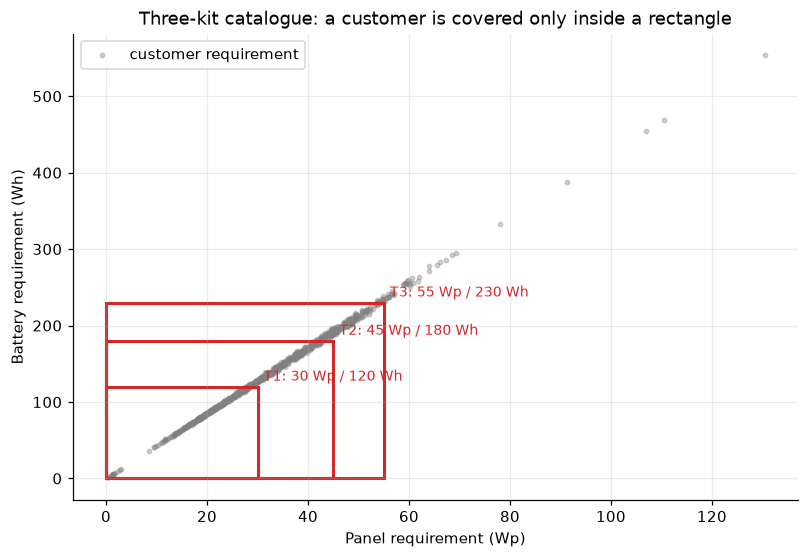

In [37]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(req.PV, req.BAT, s=8, alpha=.35, color="grey", label="customer requirement")
for _, t in catalogs["3 kits"].iterrows():
    ax.add_patch(plt.Rectangle((0, 0), t.PV_Wp, t.Battery_Wh, fill=False, lw=2, ec="C3"))
    ax.annotate(f"{t.Tier}: {t.PV_Wp:.0f} Wp / {t.Battery_Wh:.0f} Wh", (t.PV_Wp, t.Battery_Wh),
                textcoords="offset points", xytext=(4, 4), color="C3", fontsize=9)
ax.set(title="Three-kit catalogue: a customer is covered only inside a rectangle",
       xlabel="Panel requirement (Wp)", ylabel="Battery requirement (Wh)"); ax.legend(); plt.show()

> **Interpretation.** Because requirements fall on one line, each kit is effectively **a point on that line** and its rectangle's corner
> sits on it. The ≈ 5% uncovered customers are the sparse tail beyond 55 Wp / 230 Wh (up to 130 Wp / 550 Wh).
> These are too few and too varied for a standard kit and are better served by a **modular add-on battery/panel**.

### 6.1 Stress tests: worse sun and customer mix

In [38]:
req_3psh = pd.DataFrame({"PV": pv["3 PSH"], "BAT": req.BAT})
stress = pd.DataFrame({name: {"Coverage at 4 PSH (%)": evaluate(catalogs[name])[1]["Coverage_%"],
                              "Coverage at 3 PSH (%)": evaluate(catalogs[name], req_3psh)[1]["Coverage_%"]}
                       for name in OPTIONS}).T
display(stress.round(1))
display(pd.crosstab(assignments["3 kits"], cluster, normalize="index").round(2))

,Coverage at 4 PSH (%),Coverage at 3 PSH (%)
1 kit,95.30,75.50
2 kits,95.30,75.50
3 kits,95.30,75.50
4 kits,95.30,75.50


Cluster,A,B,C,D
row_0,,,,
Not covered,0.15,0.21,0.15,0.49
T1,0.10,0.31,0.55,0.04
T2,0.21,0.23,0.39,0.17
T3,0.33,0.17,0.15,0.36


> **Interpretation.** **Sun risk:** if the site has 3 rather than 4 peak sun hours, coverage falls from **95.3% to 75.5%**, and one in five
> customers would be under-panelled. The drop is identical for every option because the largest panel (55 Wp) is the same
> in all of them. More kits cannot fix a resource problem; only **larger panels** can.
> **Customer mix:** T1 is **55% flat-profile C**, while T3 is mostly peaky **A (33%) and D (36%)**, and **49% of uncovered
> customers are late-peak D**. Shape therefore predicts kit size only loosely, but late-evening users are clearly the hardest to serve.

## 7. Synthesis
The headline cell reprints key numbers so the narrative always matches the latest run.

In [39]:
t3 = catalogs["3 kits"]
headline = [
    ("Median customer daily use (Wh/day)",   customer_stats["Median_Wh"].median(),         "{:.1f}"),
    ("Median customer Q90 (Wh/day)",         customer_stats["Q90_Wh"].median(),            "{:.1f}"),
    ("Customers night-heavy (> 60% night)",  (day_night["Night_Share"] > .6).mean(),       "{:.1%}"),
    ("Customers peaking 17–20 h",            peak_hour.between(17, 20).mean(),             "{:.1%}"),
    ("Median ACF lag 1",                     acf_df.loc[1].median(),                       "{:.2f}"),
    ("Median PACF lag 7",                    pacf_ok.loc[7].median(),                      "{:.3f}"),
    ("YoY: share lower one year later",      (yoy["Change_Wh"] < 0).mean(),                "{:.1%}"),
    ("YoY: median change (Wh/day)",          yoy["Change_Wh"].median(),                    "{:.1f}"),
    ("Median LFP battery, 1 day (Wh)",       battery_lfp.median(),                         "{:.0f}"),
    ("Median panel, 4 PSH (Wp)",             pv_4.median(),                                "{:.0f}"),
    ("3-kit coverage at 4 PSH",              comparison.loc["3 kits", "Coverage_%"] / 100, "{:.1%}"),
    ("3-kit coverage at 3 PSH",              stress.loc["3 kits", "Coverage at 3 PSH (%)"] / 100, "{:.1%}"),
    ("3-kit excess battery vs custom",       comparison.loc["3 kits", "Excess_Batt_%"] / 100, "{:.1%}"),
]
for label, v, fmt in headline:
    print(f"{label:<40} {fmt.format(v):>8}")
print("\n3-kit catalogue:"); print(t3.to_string(index=False))

Median customer daily use (Wh/day)           56.9
Median customer Q90 (Wh/day)                 95.2
Customers night-heavy (> 60% night)         21.9%
Customers peaking 17–20 h                   65.0%
Median ACF lag 1                             0.63
Median PACF lag 7                           0.045
YoY: share lower one year later             61.6%
YoY: median change (Wh/day)                  -6.2
Median LFP battery, 1 day (Wh)                124
Median panel, 4 PSH (Wp)                       29
3-kit coverage at 4 PSH                     95.3%
3-kit coverage at 3 PSH                     75.5%
3-kit excess battery vs custom              24.3%

3-kit catalogue:
Tier  PV_Wp  Battery_Wh
  T1  30.00      120.00
  T2  45.00      180.00
  T3  55.00      230.00


### Chain of reasoning

**Question.** What panel and battery capacities should the PAYGo company offer?

**Observations**
1. **Small but uneven demand.** Median customer 57 Wh/day (Q90 95 Wh), with 10× differences between customers.
2. **Base load dominates.** ≈ 1.8 Wh every hour (≈ 43 Wh/day) runs all night, and the evening peak adds relatively little.
3. **Variability is individual.** 37.5% of customers vary by more than their typical day, and ≈ 100 are on/off users.
4. **Four overlapping shapes.** Early-peak A, daytime B, flat C (largest, 41%) and late-peak D (highest energy).
   Shapes form a continuum (silhouette ≈ 0.21) and do not determine size.
5. **Persistence, not weekly cycles.** Lag-1 ACF 0.63, PACF ≈ 0 by lag 7. Good and bad days come in runs.
6. **Year-2 decline is modest and partly statistical.** 62% decline (median −6.2 Wh/day), but low starters rise
   (+32) and high starters fall (−26), which is regression to the mean. Late-peak D declines most.
7. **Hardware is small.** Median 124 Wh LFP and 29 Wp at 4 PSH; three kits cover 95% with ≈ 24–31% excess.

**Explanation.** Most energy is a steady base load plus an evening peak, so most energy passes through the battery.
Persistent high-use runs and cloudy runs, not single days, stress the system. The lecture sizing method ties battery
and panel to one number (Q90), which hides timing differences.

**Recommendation (hypotheses to test)**
* Offer **three LFP kits**: **30 Wp / 120 Wh**, **45 Wp / 180 Wh** and **55 Wp / 230 Wh**, plus a modular add-on for the top ~5%.
* **Confirm the service area's worst-month sun hours first.** At 3 PSH, coverage drops to 75%, and panels, not more kits, are the fix.
* Consider a **smaller-battery variant for day-heavy customers** (cluster A needs only 38% of full autonomy for its nights).
* Offer **appliance bundles targeting the evening** (efficient TV/lights) to late-peak D, who are both high-use and most often uncovered.

**Caveats.** Observed use is *delivered* energy and may understate demand where systems were constrained.
Hourly data hides short power peaks. Elapsed days are not calendar dates. Sun-hour scenarios do not identify locations.
§8 tests whether low-use spells reflect **lack of sun, the battery, payment or data problems**.

## 8. Outage & assumption investigation (beyond the protocol)
**Question.** When a customer's use collapses, what is the most likely cause?
Without PV, battery, weather or payment data we cannot *prove* a cause, but each cause leaves a different fingerprint:

| Possible cause | Length | Onset | During the spell | Recovery |
|---|---|---|---|---|
| **No sun > battery autonomy** | short (1–4 days) | gradual; evening cut first | some daytime use survives; **night hit hardest** | gradual, as sun returns |
| **PAYGo lockout** | ≈ payment period (days → weeks) | abrupt | **zero in all hours**, including daylight | abrupt return to old level |
| **Absence / fault** | variable, often long | abrupt | zero or constant | may never return |
| **Telemetry gap-fill** | any | abrupt | **exactly repeated value** (flat line) | abrupt |

We test these fingerprints step by step, then compare observed spells with a **weather simulation** of the proposed design.

### 8.1 Flat-line segments: real standby load or filled data?

Hours inside flat runs: 28.0%
Systems with > 20% flat hours: 64.3%
Mostly-flat days: 27.9% of all customer-days


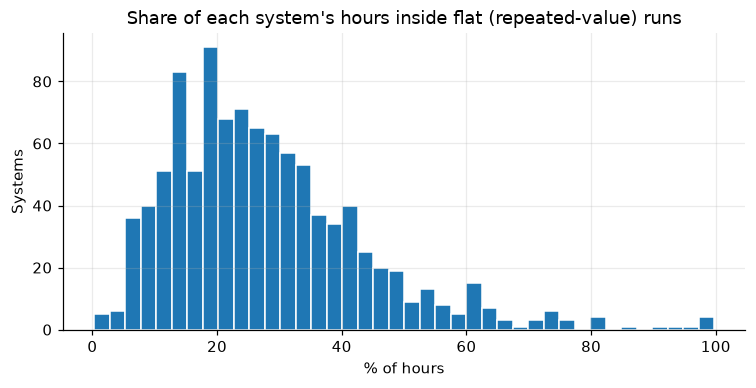

In [40]:
MIN_FLAT_HOURS = 6                                    # ≥ 6 identical consecutive hourly values
Xh = hourly_365.to_numpy()
# identical to the previous hour AND above zero (true zeros are handled separately as shutdowns)
same = np.vstack([np.zeros((1, Xh.shape[1]), bool), (np.diff(Xh, axis=0) == 0) & (Xh[1:] > 0)])
closes_run = pd.DataFrame(same.astype(int)).rolling(MIN_FLAT_HOURS - 1).sum().eq(MIN_FLAT_HOURS - 1)
flat = closes_run.copy()
for s in range(1, MIN_FLAT_HOURS):                     # mark every hour inside the run
    flat |= closes_run.shift(-s, fill_value=False)
flat.columns = hourly_365.columns

flat_share = flat.mean()
flat_day = flat.groupby(d365).mean() > 0.5            # a day that is mostly flat
flat_day.index = daily_365.index

print(f"Hours inside flat runs: {flat.to_numpy().mean():.1%}")
print(f"Systems with > 20% flat hours: {(flat_share > .2).mean():.1%}")
print(f"Mostly-flat days: {flat_day.to_numpy().mean():.1%} of all customer-days")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(flat_share * 100, bins=40, edgecolor="white")
ax.set(title="Share of each system's hours inside flat (repeated-value) runs", xlabel="% of hours", ylabel="Systems"); plt.show()

> **How to read this (run the cell).** Real appliance use varies from hour to hour, so **six identical non-zero values
> in a row are very unlikely unless the logger repeated or filled a value**. If flat hours are a large share (e.g. > 5%) and
> concentrated in some systems, those periods are probably **data gaps disguised as consumption**. They should be
> excluded from sizing and outage analysis (done below) and reported to the data provider. If flat hours are rare,
> the constant base load seen in §3.2 is more likely real standby consumption.

### 8.2 Find low-use spells and read their fingerprints
A **low day** = daily energy < 25% of the customer's own median (only customers with median ≥ 10 Wh/day).
A **spell** = consecutive low days. For each spell we measure its length, the share of truly zero days, how much
**day vs night** use survives, how it started (the 2 days before) and how it ended (the 2 days after).

In [41]:
LOW_FRAC, MIN_MEDIAN = 0.25, 10
med_total = daily_365.median()
med_dayE, med_nightE = E_day.median(), E_night.median()
eligible_sys = med_total[med_total >= MIN_MEDIAN].index

spells = []
for s in eligible_sys:
    low = (daily_365[s] < LOW_FRAC * med_total[s]).to_numpy()
    t = 0
    while t < len(low):
        if not low[t]:
            t += 1; continue
        start = t
        while t < len(low) and low[t]:
            t += 1
        end = t                                             # spell covers [start, end)
        idx = range(start, end)
        pre  = daily_365[s].iloc[max(0, start - 2): start]
        post = daily_365[s].iloc[end: end + 2]
        spells.append({
            "System": s, "Start": start, "Length": end - start,
            "Zero_frac":   (daily_365[s].iloc[idx] < 1).mean(),
            "Flat_frac":   flat_day[s].iloc[idx].mean(),
            "Day_ratio":   E_day[s].iloc[idx].mean()   / max(med_dayE[s], 1e-9),
            "Night_ratio": E_night[s].iloc[idx].mean() / max(med_nightE[s], 1e-9),
            "Pre_ratio":   pre.mean()  / med_total[s] if len(pre)  else np.nan,
            "Post_ratio":  post.mean() / med_total[s] if len(post) else np.nan,
        })
spells = pd.DataFrame(spells)

def classify(r):
    if r.Flat_frac >= 0.5:  return "Flat / possible data fill"
    if r.Zero_frac >= 0.8:  return "Full shutdown (lockout/absence/fault)"
    if r.Night_ratio < r.Day_ratio and r.Length <= 4:
        return "Short, night-hit (weather/battery-consistent)"
    return "Other partial low use"
spells["Type"] = spells.apply(classify, axis=1)

print(f"Customers analysed: {len(eligible_sys)} | spells found: {len(spells)} | "
      f"customers with ≥ 1 spell: {spells.System.nunique()}")
spells.groupby("Type").agg(Spells=("Length", "size"), Customers=("System", "nunique"),
                           Median_length=("Length", "median"), P90_length=("Length", lambda x: x.quantile(.9)),
                           Median_pre=("Pre_ratio", "median"), Median_post=("Post_ratio", "median")).round(2)

Customers analysed: 888 | spells found: 10081 | customers with ≥ 1 spell: 857


,Spells,Customers,Median_length,P90_length,Median_pre,Median_post
Type,,,,,,
Flat / possible data fill,6438,822,2.00,8.00,1.05,1.08
Full shutdown (lockout/absence/fault),1461,372,3.00,16.00,1.03,1.04
Other partial low use,1430,477,4.00,18.00,0.96,0.98
"Short, night-hit (weather/battery-consistent)",752,323,1.00,4.00,0.93,0.94


> **How to read this (run the cell).**
> * **Short, night-hit spells** (night falls more than day, ≤ 4 days) fit **"no sun > autonomy" or battery depletion**.
>   A *Median_pre* below 1 (use already falling before the spell) strengthens this reading.
> * **Full shutdowns** with *Median_pre ≈ 1* and *Median_post ≈ 1* (normal right before and right after) fit
>   **PAYGo lockout**: service stops and restarts at the old level, which weather cannot do.
> * **Flat** spells are likely data problems and should not be blamed on customers or weather.
> * Compare the **customer counts**: whichever type touches the most customers is the company's biggest service issue.

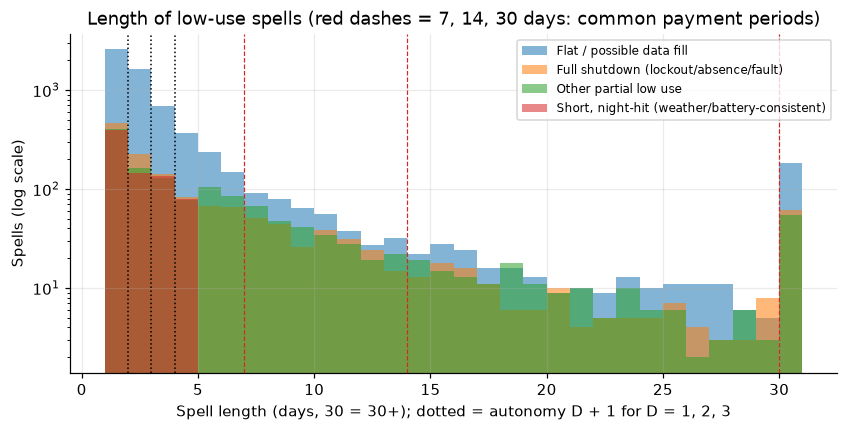

In [42]:
fig, ax = plt.subplots(figsize=(9, 4))
bins_len = np.arange(1, 32)
for typ, grp in spells.groupby("Type"):
    ax.hist(grp.Length.clip(upper=30), bins=bins_len, alpha=.55, label=typ)
for d in [1, 2, 3]:
    ax.axvline(d + 1, color="k", ls=":", lw=1)
for d in [7, 14, 30]:
    ax.axvline(d, color="C3", ls="--", lw=.8)
ax.set_yscale("log")
ax.set(title="Length of low-use spells (red dashes = 7, 14, 30 days: common payment periods)",
       xlabel="Spell length (days, 30 = 30+); dotted = autonomy D + 1 for D = 1, 2, 3", ylabel="Spells (log scale)")
ax.legend(fontsize=8); plt.show()

> **How to read this (run the cell).** Weather-driven shortfalls should be **mostly 1–3 days**: a system with D days of
> autonomy only runs short when a cloudy spell lasts longer than D, and tropical cloudy spells are usually short.
> **Bumps near 7, 14 or 30 days** in full-shutdown spells would point to **payment periods** (weekly or monthly plans).
> A long flat tail (> 30 days) points to absence, faults or abandonment.

### 8.3 Battery-depletion test: does a heavy day cause an evening cut-off the next day?
**Evening cut-off day** = night use < 30% of the customer's median night *while* daytime use is ≥ 50% of normal.
The system worked by day but not at night, the typical sign of an empty battery.
If depletion is real, cut-offs should be **more likely after a heavy day** (Lecture 7: "earlier cutoff after heavier use")
and should **repeat on consecutive days** (like cloudy spells).

In [43]:
Dn = E_night[eligible_sys].div(med_nightE[eligible_sys])
Dd = E_day[eligible_sys].div(med_dayE[eligible_sys].where(med_dayE[eligible_sys] > 0))
cutoff = (Dn < 0.30) & (Dd >= 0.50)

total_prev = daily_365[eligible_sys].shift(1)
heavy_prev = total_prev.gt(daily_365[eligible_sys].quantile(.75))
light_prev = total_prev.le(daily_365[eligible_sys].median())
cut_prev = cutoff.shift(1).fillna(False).astype(bool)

cf = cutoff.astype(float)
base_rate = cf.to_numpy().mean()
depletion = pd.Series({
    "All days":                         base_rate,
    "After a heavy day (> own Q75)":    np.nanmean(cf.where(heavy_prev).to_numpy()),
    "After a light day (≤ own median)": np.nanmean(cf.where(light_prev).to_numpy()),
    "After a cut-off day":              np.nanmean(cf.where(cut_prev).to_numpy()),
}).to_frame("P(evening cut-off)")
display(depletion.style.format("{:.2%}"))
print(f"Customers with ≥ 5 cut-off days: {(cutoff.sum() >= 5).sum()} of {len(eligible_sys)}")

,P(evening cut-off)
All days,0.91%
After a heavy day (> own Q75),0.42%
After a light day (≤ own median),1.29%
After a cut-off day,31.80%


Customers with ≥ 5 cut-off days: 155 of 888


> **How to read this (run the cell).**
> * P(cut-off | heavy day) **clearly above** P(cut-off | light day) → heavy use drains the battery, consistent with
>   **undersized storage**. The customers affected are candidates for a bigger kit.
> * P(cut-off | previous cut-off) **far above** the base rate → cut-offs come in runs, like **multi-day cloudy spells**.
> * If both conditional rates are close to the base rate, cut-offs are more likely scheduled behaviour (e.g. lights off
>   by choice) or evening lockouts.

### 8.4 Is night use capped by the battery?
The lecture's case system is **12 V × 17 Ah ≈ 204 Wh lead-acid**. At 50% DoD and η_dis = 0.894, it delivers only
≈ **91 Wh per night** without sun. If customers use that hardware, night energy should **pile up just below ~91 Wh**
and rarely exceed it, and heavier users would run short more often.

Case battery delivers ≈ 91 Wh without sun
Customer-nights above that: 2.64%
Customer-days (total) above that: 19.2%


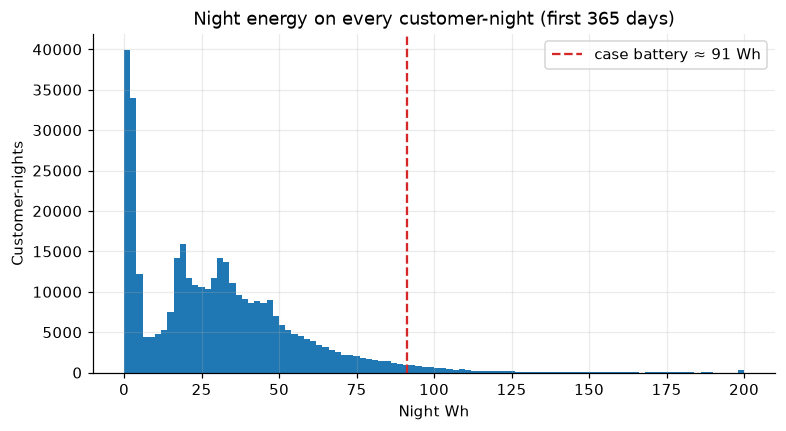

,Customers,Median_autonomy,Mean_short_spells
Autonomy_band,,,
Lowest,222,0.89,0.77
Low,222,1.32,0.73
High,222,1.76,0.76
Highest,222,2.62,1.13


Customers whose median day exceeds the case battery (autonomy < 1 day): 17.3%


In [44]:
case_nominal_Wh = 12 * 17
case_delivered  = case_nominal_Wh * DoD_lead * eta_dis_lead           # ≈ 91 Wh
night_all = pd.Series(E_night.to_numpy().ravel()).dropna()

print(f"Case battery delivers ≈ {case_delivered:.0f} Wh without sun")
print(f"Customer-nights above that: {(night_all > case_delivered).mean():.2%}")
print(f"Customer-days (total) above that: {(daily_valid > case_delivered).mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(night_all.clip(upper=200), bins=100, edgecolor="none")
ax.axvline(case_delivered, color="C3", ls="--", label=f"case battery ≈ {case_delivered:.0f} Wh")
ax.set(title="Night energy on every customer-night (first 365 days)", xlabel="Night Wh", ylabel="Customer-nights")
ax.legend(); plt.show()

# Implied autonomy: days the case battery could carry the customer's median day with no sun
implied_autonomy = case_delivered / med_total.clip(lower=1)
spell_rate = spells[spells.Type.str.startswith("Short")].groupby("System").size().reindex(eligible_sys, fill_value=0)
test = pd.DataFrame({"Implied_autonomy_days": implied_autonomy[eligible_sys], "Short_spells": spell_rate})
test["Autonomy_band"] = pd.qcut(test.Implied_autonomy_days, 4, labels=["Lowest", "Low", "High", "Highest"])
display(test.groupby("Autonomy_band", observed=True).agg(
    Customers=("Short_spells", "size"), Median_autonomy=("Implied_autonomy_days", "median"),
    Mean_short_spells=("Short_spells", "mean")).round(2))
print(f"Customers whose median day exceeds the case battery (autonomy < 1 day): {(implied_autonomy < 1).mean():.1%}")

> **How to read this (run the cell).**
> * A **pile-up and a sharp drop just below the red line** means night use hits a hardware ceiling, so observed use
>   **understates demand** and sizing from it is too small. A smooth tail crossing the line means the real systems have
>   more usable storage than the case assumption.
> * If customers with the **lowest implied autonomy have the most short spells**, weather/battery depletion is a real
>   driver: heavy users run out first when the sun is weak. A flat pattern across bands points to non-weather causes.

### 8.5 Weather simulation: how often does "no sun" beat the days of autonomy?
We run the **proposed LFP design** (Q90, D days, 4 PSH panel) against each customer's *actual* daily day/night loads,
with simulated weather:

* **Sunny day:** PV = panel × 4 h × 0.85. **Cloudy day:** PV = 25% of that.
* Weather follows a two-state Markov chain. P(sunny → cloudy) = 0.15. P(cloudy → cloudy) = *p_cc* sets how long cloudy
  spells last (mean length = 1 / (1 − p_cc)).
* Each day, PV serves daytime load first, the surplus charges the battery (√η_rt), and the night load is drawn from the battery.

The cloudy-spell assumptions are **illustrative, not measured**. Replace them with local rainy-season data when the
service area is known.

In [45]:
CLOUDY_FACTOR, P_SUNNY_TO_CLOUDY, N_RUNS = 0.25, 0.15, 20
eta_ch = np.sqrt(eta_rt_lfp)

def simulate(D_days, p_cc, H=4, runs=N_RUNS, seed=SEED):
    rng = np.random.default_rng(seed)
    Ed, En = E_day.to_numpy(), E_night.to_numpy()                  # days x customers
    cap = (D_days * Q90_daily / (DoD_lfp * eta_dis_lfp)).to_numpy() * DoD_lfp   # usable Wh
    panel_Wp = (Q90_pv / (H * f_pv)).to_numpy()                   # panel sized at H peak sun hours
    pv_sunny = panel_Wp * H * f_pv                                   # Wh produced on a sunny day
    n_days, n_sys = Ed.shape
    short = np.zeros((runs, n_days, n_sys), bool)
    for r in range(runs):
        soc = cap.copy()
        cloudy = False
        for t in range(n_days):
            cloudy = rng.random() < (p_cc if cloudy else P_SUNNY_TO_CLOUDY)
            pv_t = pv_sunny * (CLOUDY_FACTOR if cloudy else 1.0)
            direct = np.minimum(pv_t, Ed[t])
            day_gap = Ed[t] - direct
            from_batt = np.minimum(day_gap / eta_dis_lfp, soc)
            soc -= from_batt
            unserved = day_gap - from_batt * eta_dis_lfp
            soc = np.minimum(cap, soc + (pv_t - direct) * eta_ch)
            night_draw = np.minimum(En[t] / eta_dis_lfp, soc)
            soc -= night_draw
            unserved += En[t] - night_draw * eta_dis_lfp
            short[r, t] = unserved > 0.05 * (Ed[t] + En[t])            # > 5% of that day's load unserved
    return short

sim_rows, sim_runs = [], {}
for p_cc in [0.5, 0.7]:
    for D_days in [1, 2, 3]:
        sh = simulate(D_days, p_cc)
        sim_runs[(D_days, p_cc)] = sh
        lolp = sh.mean(axis=(0, 1))                                    # per customer
        sim_rows.append({"Mean cloudy spell (days)": round(1 / (1 - p_cc), 1), "Autonomy D": D_days,
                         "P(spell > D)": p_cc ** D_days,
                         "Median customer: short days/yr": np.median(lolp) * 365,
                         "Customers with > 10 short days/yr": (lolp * 365 > 10).mean()})
sim_table = pd.DataFrame(sim_rows)
display(sim_table.style.hide(axis="index").format({"Mean cloudy spell (days)": "{:.1f}", "P(spell > D)": "{:.0%}", "Median customer: short days/yr": "{:.1f}",
                                "Customers with > 10 short days/yr": "{:.1%}"}))

Mean cloudy spell (days),Autonomy D,P(spell > D),Median customer: short days/yr,Customers with > 10 short days/yr
2.0,1,50%,45.4,100.0%
2.0,2,25%,23.4,94.4%
2.0,3,12%,15.0,74.4%
3.3,1,70%,74.7,100.0%
3.3,2,49%,48.7,99.6%
3.3,3,34%,36.4,98.3%


> **How to read this (run the cell).**
> * **P(spell > D)** is the core of the "coincidence" question: the chance that a cloudy spell outlasts the battery.
>   With 2-day spells (p_cc = 0.5), half of cloudy spells beat D = 1 but only 12.5% beat D = 3.
> * The **short days/yr** columns show what that means for customers. If D = 1 gives only a few short days per year,
>   the lecture's 1-day assumption is adequate. If it gives weeks, the company should move to D = 2 or offer a backup.
> * Compare 0.5 vs 0.7: longer rainy spells raise shortfalls sharply, so **local rainy-season data** is needed to finalize D.

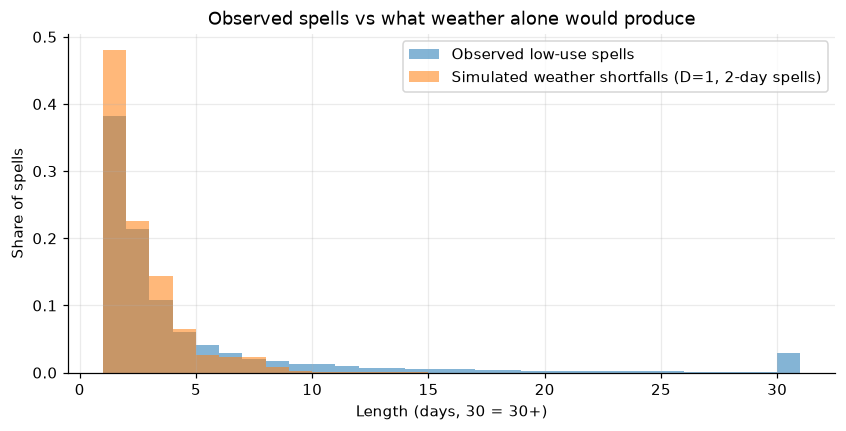

Observed spells ≥ 5 days: 23.6% | simulated weather shortfalls ≥ 5 days: 8.6%


In [46]:
def run_lengths(mask_2d):
    out = []
    for col in mask_2d.T:
        t = 0
        while t < len(col):
            if col[t]:
                s = t
                while t < len(col) and col[t]: t += 1
                out.append(t - s)
            else:
                t += 1
    return np.array(out)

sim_len = run_lengths(sim_runs[(1, 0.5)][0][:, [daily_365.columns.get_loc(s) for s in eligible_sys]])
obs_len = spells.Length.to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
b = np.arange(1, 32)
ax.hist(np.clip(obs_len, 1, 30), bins=b, density=True, alpha=.55, label="Observed low-use spells")
ax.hist(np.clip(sim_len, 1, 30), bins=b, density=True, alpha=.55, label="Simulated weather shortfalls (D=1, 2-day spells)")
ax.set(title="Observed spells vs what weather alone would produce", xlabel="Length (days, 30 = 30+)", ylabel="Share of spells")
ax.legend(); plt.show()
print(f"Observed spells ≥ 5 days: {(obs_len >= 5).mean():.1%} | simulated weather shortfalls ≥ 5 days: {(sim_len >= 5).mean():.1%}")

> **How to read this (run the cell).** Weather alone produces mostly **1–3-day** shortfalls. If observed spells ≥ 5 days
> are **much more common** than simulated ones, long outages are **not explained by lack of sun**. They point to
> lockouts, absence, faults or data gaps (see 8.2). If the two distributions look alike, weather plus limited autonomy is
> a sufficient explanation.

### 8.6 Other assumptions: are timestamps in local time?
The sharp population peak at **17:00** is early for evening lighting in the tropics (sunset ≈ 18:00–18:30).
If the logger records UTC and the systems are in UTC+2/+3 (e.g. East Africa), every clock hour is shifted.
The fixed 06–17 day window would then be misplaced, and **night share (and battery need) would be misstated**.

In [47]:
rows = []
for shift in [0, 1, 2, 3]:
    local = (h365 + shift) % 24
    is_day_s = pd.Series(local).isin(DAY_HOURS).to_numpy()
    night_share_s = hourly_365[~is_day_s].sum() / hourly_365.sum()
    peak_local = (peak_hour + shift) % 24
    rows.append({"Hours added": shift, "Most common peak (local h)": int(peak_local.mode()[0]),
                 "Median night share": night_share_s.median(),
                 "Night-heavy customers (> 60%)": (night_share_s > .6).mean()})
pd.DataFrame(rows).set_index("Hours added").style.format({"Median night share": "{:.2f}", "Night-heavy customers (> 60%)": "{:.1%}"})

,Most common peak (local h),Median night share,Night-heavy customers (> 60%)
Hours added,,,
0,17,0.52,21.9%
1,18,0.53,25.7%
2,19,0.56,28.8%
3,20,0.56,26.9%


> **How to read this (run the cell).** With **+2 or +3 hours**, the common peak moves to **19–20 h**, a far more typical
> lighting peak. If that shift also raises the median night share and the share of night-heavy customers, the current
> analysis **understates battery dependence**. Before finalizing kit sizes, the company should confirm the logger's time zone.

### 8.7 What the outage investigation tells the company
Fill in after running (each line is decided by the result named in brackets):

1. **Data quality** [§8.1]: if flat runs are common, fix telemetry before trusting outage counts or zero-day statistics.
2. **Weather vs autonomy** [§8.5]: if D = 1 leaves more than ~10 short days/yr for many customers under realistic spells,
   move the standard kits to **D = 2** or sell a **battery add-on** in rainy regions.
3. **Battery depletion** [§8.3–8.4]: if cut-offs follow heavy days or night use piles up at the case-battery limit,
   observed demand is **suppressed**. Size kits above current use, and target flagged customers for upgrades.
4. **Lockouts** [§8.2]: if abrupt full shutdowns with quick full recovery dominate, most "outages" are **payment-related**.
   Link to payment logs, and consider flexible top-ups rather than bigger hardware.
5. **Time zone** [§8.6]: confirm logger time before using the day/night split for pricing or battery design.

**Data the company should add to confirm causes:** payment timestamps and lockout logs, battery voltage/state-of-charge,
PV current, local weather or satellite irradiance, and installation dates.

### References
* Perriment et al. (2025). Hourly SHS consumption dataset, Oxford Research Archive, v1.0.
* NIST/SEMATECH e-Handbook of Statistical Methods: autocorrelation and seasonality.
* scikit-learn user guide: k-means clustering.
* 04-782 Lecture 7 (Solar Home Systems) and Lecture 8 (SHS Analytical Methods).